# Murshed – Mental Health Problems Classifier

### ARTI452: Natural Language Processing
**Imam Abdulrahman Bin Faisal University**  
College of Computer Science and Information Technology

### Team Members

| Student Name | Student ID |
|---|---|
| Aleen Alzahrani | 2240006885 |
| Najaf Almohsen | 2240003480 |
| Haya Alwuhaibi | 2240007544 |

## Project Overview

Murshed is an Arabic Natural Language Processing (NLP) system designed to classify mental health consultation questions into six predefined categories. The system aims to help users identify a relevant mental health support category based on their written questions.

Two classification methods are implemented and compared:

1. **Semantic Similarity + K-Nearest Neighbours (KNN)**
2. **TF-IDF + Linear Support Vector Machine (SVM)**

## 1. Environment Setup and Libraries

### 1.1 Install & Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import re
import unicodedata
import html
from collections import Counter

from pathlib import Path

import nltk
from nltk.corpus import stopwords
from nltk.stem.isri import ISRIStemmer

from sklearn.model_selection import train_test_split

from IPython.display import display

import random

nltk.download("stopwords", quiet=True)

True

### 1.2 Configuration and Reproducibility

In [2]:
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path("Dataset")
OUTPUT_DIR = Path("processed_data")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

print("Dataset directory:", DATA_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

assert DATA_DIR.exists(), "Dataset folder not found."

Dataset directory: /content/Dataset
Output directory: /content/processed_data


## 2. Data Acquisition and Preprocessing

### 2.1 Dataset Loading

In [3]:
# Find and list all CSV files in the dataset directory
csv_files = sorted(DATA_DIR.glob("*.csv"))

print("Number of CSV files:", len(csv_files))

for file in csv_files:
    print(file.name)

if not csv_files:
    raise FileNotFoundError("No CSV files found.")

Number of CSV files: 7
Behavioral_Psychological_Conditions.csv
Childhood_Psychological_Problems.csv
Neuropsychological_Conditions.csv
Other_Psychological_and_Behavioral_Issues.csv
Personality_and_Self_Development.csv
Psychological_Issues_and_Guidance.csv
Psychotic_Disorders.csv


In [4]:
# Read CSV files and inspect their columns and sample rows
def read_csv_file(path, nrows=None):
    for encoding in ["utf-8-sig", "utf-8", "cp1256"]:
        try:
            return pd.read_csv(
                path,
                encoding=encoding,
                nrows=nrows
            )
        except UnicodeDecodeError:
            continue

    raise ValueError(f"Unable to decode: {path.name}")


for file in csv_files:
    sample = read_csv_file(file, nrows=3)

    print("\n" + "=" * 60)
    print("File:", file.name)
    print("Columns:", sample.columns.tolist())

    display(sample.head(2))


File: Behavioral_Psychological_Conditions.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,أتعبتني الخيالات الانفعالية، فما هو العلاج؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ محمد حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسلام ويب...,د. محمد عبد العليم,2550657,2024-10-15,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة
1,أعيش في الخيال أكثر من الواقع، فكيف أتخلص من ذلك؟,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، عمري 17 سنة، منذ صغري وأنا أعاني من الخيال بشكل مفرط، وأتخيل شخصيات ال...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ نور حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nحقيقةً قرأتُ سؤالك...,د. مأمون مبيض,2544364,2024-06-27,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة



File: Childhood_Psychological_Problems.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,أحتاج لتوجيهكم بشأن الروضة التي تناسب ابنتي أكثر..,السلام عليكم ورحمة الله وبركاته.\n\nابنتي عمرها 4 سنوات، وأريد البحث عن روضة مناسبة لها، من حيث المكان، والاهتمام، و...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ مريم حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنتفهم تمامًا مخاو...,أ. فيصل العشاري,2545743,2024-07-24,مشاكل الطفل النفسية - أمور أخرى متعلقة بالصحة النفسية للطفل
1,كيف أعود طفلي على الذهاب إلى الحمام بنفسه؟,ابني بعمر سنتين وعشرة أشهر، بدأت في تعليمه استعمال الحمام قبل سبعة أشهر، وإلى اليوم لا يطلب مني الذهاب إلى الحمام، و...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ سائلة حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nيجب ألا يقترن ال...,د. عطية إبراهيم محمد,2546073,2024-07-21,مشاكل الطفل النفسية - أمور أخرى متعلقة بالصحة النفسية للطفل



File: Neuropsychological_Conditions.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,أشعر بالاكتئاب في الصباح وأتحسن في المغرب.. ما العلة؟,السلام عليكم.\n\nعمري 16 سنة، كنت مريضًا بالوسواس القهري في شهر 6، فذهبت للطبيبة النفسية فكتبت لي (Faverin 100)، حبت...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ zeyad حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في استشارات...,د. محمد عبد العليم,2551445,2024-11-17,الحالات النفسية العصبية - الاكتئاب - الاكتئاب عمومًا
1,هل يمكن الجمع بين إنفرانيل وسيبرالكس لعلاج الاكتئاب والهلع؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني من الاكتئاب ونوبات الفزع، ووصف لي الطبيب: الإنفرانيل 25 ملغ، والسيبرالكس 15...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ إبراهيم حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك -أخي الفا...,د. مأمون مبيض,2551317,2024-11-10,الحالات النفسية العصبية - الاكتئاب - الاكتئاب عمومًا


... (4 outputs left out)


File: Psychological_Issues_and_Guidance.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,ذكرياتي المزعجة تداهمني عند الاستيقاظ وتفسد صباحي، فماذا أفعل؟,السلام عليكم ورحمة الله وبركاته\n\nهناك شيء يحدث معي منذ فترة طويلة في الصباح، وقبل الاستيقاظ من النوم بقليل، حينما ...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ أمل حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسلام و...,د. محمد عبد العليم,2549369,2024-09-17,قضايا وإرشادات نفسية عامة - أخرى
1,هل يمكن دراسة علم النفس عن طريق الكتب فقط؟,السلام عليكم ورحمة الله وبركاته\n\nأسأل: ما هي طريق الوصول لفهم وتحليل الشخصيات والمشاكل النفسية، وفهم النفس وطريقة ...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ بنية حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك -بُنيَّتي...,د. مأمون مبيض,2547801,2024-08-25,قضايا وإرشادات نفسية عامة - أخرى



File: Psychotic_Disorders.csv
Columns: ['Question Title', 'Question', 'Answer', 'Doctor Name', 'Consultation Number', 'Date of Answer', 'Hierarchical Diagnosis']


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis
0,زميلي يشكو من أعراض الذهان الجانبية، فكيف يتخلص منها؟,السلام عليكم ورحمة الله وبركاته.\n\nسؤالي له بعد طبي وشرعي: هنالك شاب في العشرين من عمره، وتعرض لمشاكل نفسية أثرت عل...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ عبد الرحمن حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسل...,د. محمد عبد العليم,2549762,2024-09-24,الأمراض الذهانية - أمور أخرى متعلقة بالأمراض الذهانية
1,لا أشعر بالرضا عن حياتي ولا علاقتي بربي، فماذا أفعل؟,السلام عليكم.\n\nأشعر بأني تائهة في الحياة، ولا أعرف من أين أبدأ! لا أشعر بالرضا عن حياتي، ولا علاقتي بربي، ولا علاق...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ Sa. حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك -أختنا الف...,د. مأمون مبيض,2547156,2024-08-07,الأمراض الذهانية - أمور أخرى متعلقة بالأمراض الذهانية


In [5]:
# The 6 selected CSV files
selected_files = [
    "Behavioral_Psychological_Conditions.csv",
    "Neuropsychological_Conditions.csv",
    "Personality_and_Self_Development.csv",
    "Psychotic_Disorders.csv",
    "Childhood_Psychological_Problems.csv",
    "Other_Psychological_and_Behavioral_Issues.csv"
]

# List to store DataFrames
all_data = []

# Loop through the 6 files
for file_name in selected_files:

    file_path = DATA_DIR / file_name
    df = read_csv_file(file_path)

    # Extract category from filename
    category = file_path.stem.replace("_", " ")

    # Add Category column
    df["Category"] = category

    # Add DataFrame to the list
    all_data.append(df)

    print(f"Loaded: {file_name} | Category: {category} | Rows: {len(df)}")

# Merge all 6 DataFrames
merged_df = pd.concat(all_data, ignore_index=True)

# Save merged dataset
merged_df.to_csv(
    OUTPUT_DIR / "Murshed_Dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Final Dataset Shape:", merged_df.shape)

display(merged_df.head())

Loaded: Behavioral_Psychological_Conditions.csv | Category: Behavioral Psychological Conditions | Rows: 2705
Loaded: Neuropsychological_Conditions.csv | Category: Neuropsychological Conditions | Rows: 24835
Loaded: Personality_and_Self_Development.csv | Category: Personality and Self Development | Rows: 4558
Loaded: Psychotic_Disorders.csv | Category: Psychotic Disorders | Rows: 1738
Loaded: Childhood_Psychological_Problems.csv | Category: Childhood Psychological Problems | Rows: 690
Loaded: Other_Psychological_and_Behavioral_Issues.csv | Category: Other Psychological and Behavioral Issues | Rows: 262
Final Dataset Shape: (34788, 8)


,Question Title,Question,Answer,Doctor Name,Consultation Number,Date of Answer,Hierarchical Diagnosis,Category
0,أتعبتني الخيالات الانفعالية، فما هو العلاج؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,بسم الله الرحمن الرحيم\nالأخ الفاضل/ محمد حفظه الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nنرحب بك في إسلام ويب...,د. محمد عبد العليم,2550657,2024-10-15,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
1,أعيش في الخيال أكثر من الواقع، فكيف أتخلص من ذلك؟,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، عمري 17 سنة، منذ صغري وأنا أعاني من الخيال بشكل مفرط، وأتخيل شخصيات ال...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ نور حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nحقيقةً قرأتُ سؤالك...,د. مأمون مبيض,2544364,2024-06-27,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
2,ما هو علاج الأفكار والخيالات الوسواسية التي تسيطر علي؟,السلام عليكم ورحمة الله وبركاته.\n\nأنا طالبة عمري 17، لما كنت صغيرة كنت أعاني من التنمُّر، وبسبب هذا صرت أتخيل شخصي...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ نور حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nأولًا: الحمد لله أ...,د. على أحمد التهامي,2543834,2024-06-23,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
3,تخيلاتي المفرطة لدرجة الهوس تشعرني بالجنون!,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ Dihia حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nالخيال هو وسيلة ...,د. عبدالمنعم محمود عبدالحكم,2541965,2024-06-03,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions
4,أعيش في أحلام اليقظة وإدمانها، فكيف أعود للواقع؟,السلام عليكم ورحمة الله وبركاته\n\nأعاني من أحلام اليقظة المرضية وإدمانها، وكنت أعاني من هذه المشكلة منذ الإعدادية، ...,بسم الله الرحمن الرحيم\nالأخت الفاضلة/ رقية حفظها الله.\nالسلام عليكم ورحمة الله وبركاته، وبعد:\n\nمرحبًا بك في استش...,د. على أحمد التهامي,2541396,2024-05-27,الحالات النفسية السلوكية - مشاكل النوم - أحلام اليقظة,Behavioral Psychological Conditions


In [6]:
# Verify the merged dataset and category distribution
print("Total Rows:", len(merged_df))
print("Number of Categories:", merged_df["Category"].nunique())

print("\nRows per Category:")
print(merged_df["Category"].value_counts())

Total Rows: 34788
Number of Categories: 6

Rows per Category:
Category
Neuropsychological Conditions                24835
Personality and Self Development              4558
Behavioral Psychological Conditions           2705
Psychotic Disorders                           1738
Childhood Psychological Problems               690
Other Psychological and Behavioral Issues      262
Name: count, dtype: int64


**Note:** Since the **Question** column will be used as the input for our classification models, we will focus our data analysis and preprocessing on this column to ensure data quality before training.

### 2.2 Exploratory Data Analysis (EDA)

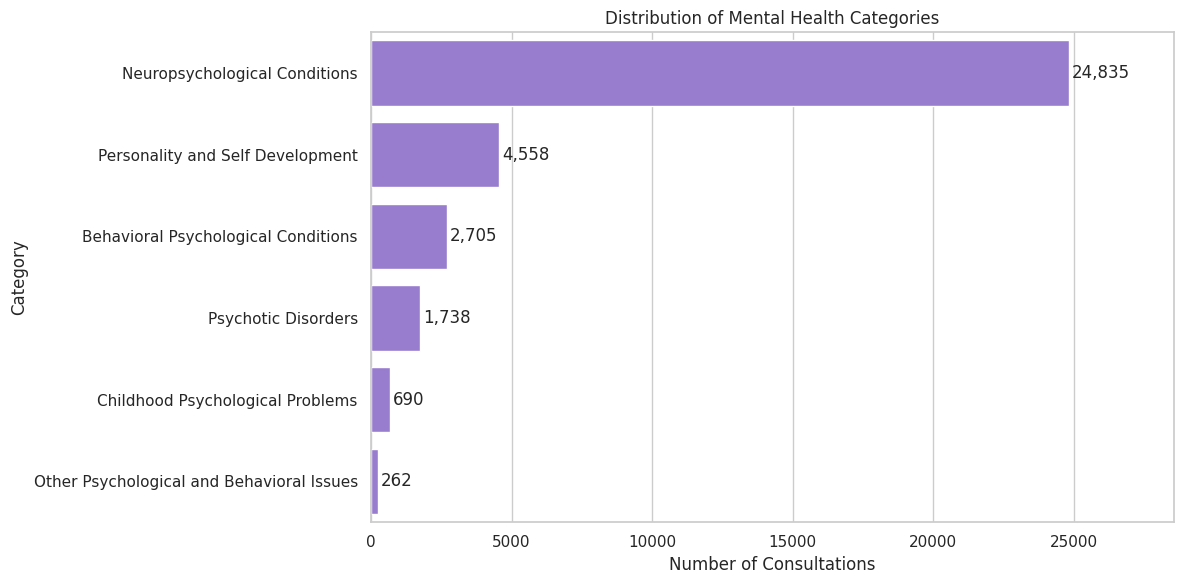

In [7]:
# Visualize the distribution of the six categories
plt.figure(figsize=(12, 6))

category_counts = merged_df["Category"].value_counts()

ax = sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    color="mediumpurple"
)

for i, count in enumerate(category_counts.values):
    ax.text(count + 100, i, f"{count:,}", va="center")

plt.title("Distribution of Mental Health Categories")
plt.xlabel("Number of Consultations")
plt.ylabel("Category")
plt.xlim(0, category_counts.max() * 1.15)
plt.tight_layout()
plt.show()

The dataset contains **34,788 consultations** across six categories. However, the data is highly imbalanced, with **Neuropsychological Conditions** representing the majority of the samples (24,835), while **Other Psychological and Behavioral Issues** has only 262 samples.

This imbalance may cause the models to favor the majority class. Therefore, **Macro F1-score** will be used alongside accuracy to evaluate performance across all categories.

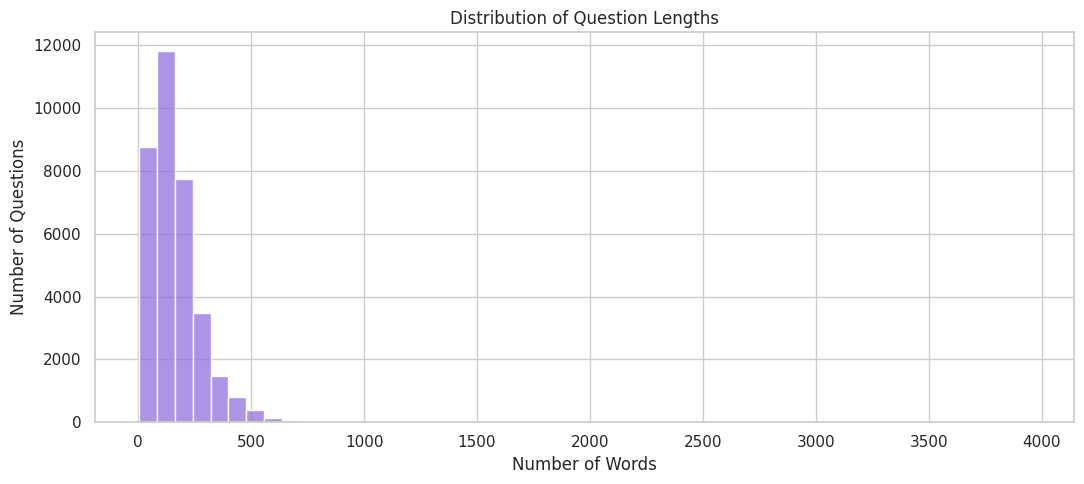

Average Question Length: 163.35
Median Question Length: 137.0
Minimum Question Length: 5
Maximum Question Length: 3946


In [8]:
# Analyze question lengths based on word count
merged_df["Question_Length"] = (merged_df["Question"].astype(str).str.split().str.len())

plt.figure(figsize=(11, 5))

sns.histplot(
    data=merged_df,
    x="Question_Length",
    bins=50,
    color="mediumpurple"
)

plt.title("Distribution of Question Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Questions")
plt.tight_layout()
plt.show()

print("Average Question Length:", round(merged_df["Question_Length"].mean(), 2))
print("Median Question Length:", merged_df["Question_Length"].median())
print("Minimum Question Length:", merged_df["Question_Length"].min())
print("Maximum Question Length:", merged_df["Question_Length"].max())

The average question length is **163.35 words**, while the median is **137 words**. Most questions are relatively short compared to the longest question, which contains **3,946 words**.

The distribution is right-skewed, indicating the presence of unusually long questions. This variation in question length is important for evaluating how well the classification models handle different input lengths.

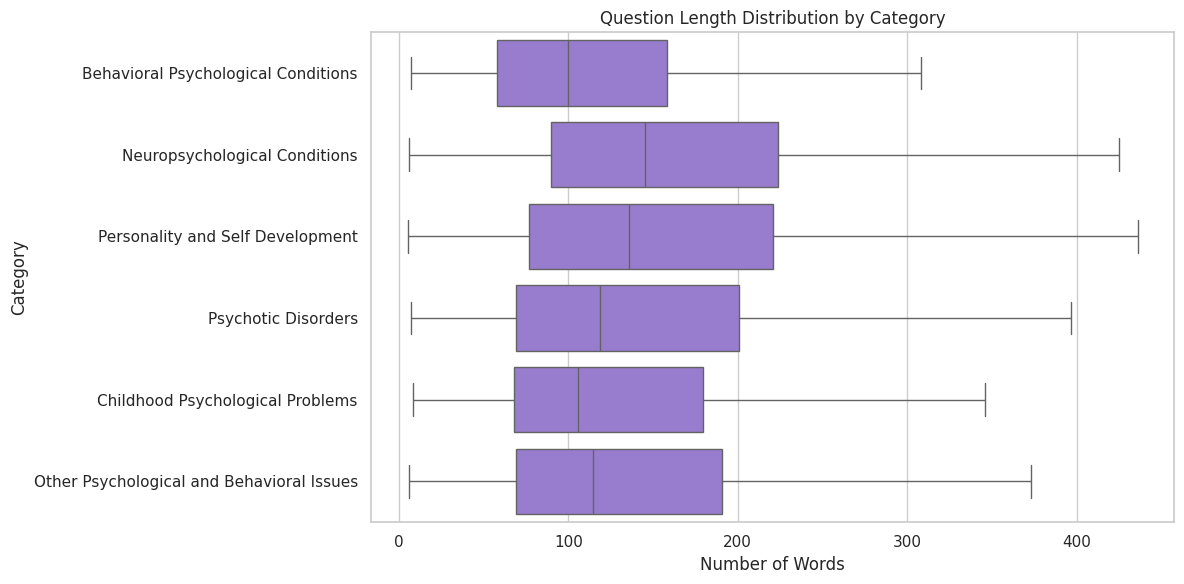

In [9]:
# Compare question lengths across the six categories
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=merged_df,
    x="Question_Length",
    y="Category",
    color="mediumpurple",
    showfliers=False
)

plt.title("Question Length Distribution by Category")
plt.xlabel("Number of Words")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

The boxplot shows that question lengths vary across the six categories. **Neuropsychological Conditions** has the highest median question length, while **Behavioral Psychological Conditions** tends to have shorter questions.

Although the distributions overlap, some categories show greater variation in question length. This suggests that question length may influence classification performance and should be considered during model evaluation.

### 2.3 Data Cleaning

In [10]:
# Check missing values and duplicate questions
print("Dataset Shape:", merged_df.shape)

print("\nMissing Questions:")
print(merged_df["Question"].isna().sum())

print("\nEmpty Questions:")
print(merged_df["Question"].fillna("").str.strip().eq("").sum())

print("\nDuplicate Questions:")
print(merged_df["Question"].duplicated().sum())

print("\nMissing Values per Column:")
display(merged_df.isna().sum())

Dataset Shape: (34788, 9)

Missing Questions:
0

Empty Questions:
0

Duplicate Questions:
12085

Missing Values per Column:


,0
Question Title,0
Question,0
Answer,0
Doctor Name,0
Consultation Number,0
Date of Answer,0
Hierarchical Diagnosis,0
Category,0
Question_Length,0


The dataset contains **12,085 duplicate rows based on the Question column**, representing approximately **34.7%** of the total dataset.

Duplicate questions may affect model evaluation and cause data leakage if they appear in both training and testing sets. Therefore, duplicates will be examined, including checking for conflicting category labels, before cleaning and splitting the dataset.

In [11]:
# Count questions appearing more than once
duplicate_counts = merged_df["Question"].value_counts()

print("Unique Questions:", merged_df["Question"].nunique())
print("Repeated Questions:", (duplicate_counts > 1).sum())
print("Extra Duplicate Rows:", merged_df["Question"].duplicated().sum())

# Check if the same question belongs to multiple categories
category_counts = merged_df.groupby("Question")["Category"].nunique()

conflicting_questions = category_counts[category_counts > 1]

print("\nQuestions with Conflicting Labels:", len(conflicting_questions))

# Display examples of conflicting labels
if len(conflicting_questions) > 0:
    conflicting_examples = merged_df[
        merged_df["Question"].isin(conflicting_questions.index)
    ][["Question", "Category"]]

    display(conflicting_examples.sort_values("Question").head(10))
else:
    print("No conflicting labels found.")

Unique Questions: 22703
Repeated Questions: 8682
Extra Duplicate Rows: 12085

Questions with Conflicting Labels: 1638


,Question,Category
16768,أبلغ من العمر 24 عامًا، وقد كنت في الصغر أنا وإخواني من المتفوقين دراسيًا، والعائلة كانت فخورة بنا، وكانت الحالة الم...,Neuropsychological Conditions
833,أبلغ من العمر 24 عامًا، وقد كنت في الصغر أنا وإخواني من المتفوقين دراسيًا، والعائلة كانت فخورة بنا، وكانت الحالة الم...,Behavioral Psychological Conditions
15779,أبلغ من العمر 24 عامًا، وقد كنت في الصغر أنا وإخواني من المتفوقين دراسيًا، والعائلة كانت فخورة بنا، وكانت الحالة الم...,Neuropsychological Conditions
13130,"أبلغ من العمر 29 سنة، وأعاني من قولون عصبي, ويسبب لي أرقا عند النوم أحيانا، فلا أستطيع النوم؛ لأني عندما أريد النوم ...",Neuropsychological Conditions
1688,"أبلغ من العمر 29 سنة، وأعاني من قولون عصبي, ويسبب لي أرقا عند النوم أحيانا، فلا أستطيع النوم؛ لأني عندما أريد النوم ...",Behavioral Psychological Conditions
15790,أبلغ من العمر 40 عامًا، عملت في مجال القانون منذ 19 عامًا تقريبًا، خلال سنوات عملي بهذا المجال ينصرف جلّ تفكيري حول ...,Neuropsychological Conditions
30187,أبلغ من العمر 40 عامًا، عملت في مجال القانون منذ 19 عامًا تقريبًا، خلال سنوات عملي بهذا المجال ينصرف جلّ تفكيري حول ...,Personality and Self Development
31512,أبلغ من العمر 40 عامًا، عملت في مجال القانون منذ 19 عامًا تقريبًا، خلال سنوات عملي بهذا المجال ينصرف جلّ تفكيري حول ...,Personality and Self Development
32410,أتوجه بالشكر الكبير لكل العاملين في هذا الموقع.\n\nأنا أعاني منذ الصغر من سوء معاملة والدي لي، فقد كنت منذ الصغر أتع...,Psychotic Disorders
2322,أتوجه بالشكر الكبير لكل العاملين في هذا الموقع.\n\nأنا أعاني منذ الصغر من سوء معاملة والدي لي، فقد كنت منذ الصغر أتع...,Behavioral Psychological Conditions


In [12]:
# Analyze conflicting labels before removing any data
conflicting_mask = merged_df["Question"].isin(conflicting_questions.index)

conflicting_df = merged_df[conflicting_mask]

print("Questions with Conflicting Labels:", len(conflicting_questions))
print("Total Rows with Conflicting Labels:", len(conflicting_df))

print("\nAffected Rows per Category:")
display(conflicting_df["Category"].value_counts())

print("\nRemaining Rows if Conflicts Are Removed:")
print(len(merged_df) - len(conflicting_df))

Questions with Conflicting Labels: 1638
Total Rows with Conflicting Labels: 4131

Affected Rows per Category:


,count
Category,
Neuropsychological Conditions,1867
Personality and Self Development,1130
Behavioral Psychological Conditions,617
Psychotic Disorders,378
Other Psychological and Behavioral Issues,88
Childhood Psychological Problems,51



Remaining Rows if Conflicts Are Removed:
30657


During data analysis, we identified **1,638 unique questions assigned to multiple categories**.

Since the **Question** column is the only input to our classification models, these conflicting labels introduce ambiguity into the training data.

We will examine the affected samples and their category distribution before removing conflicting questions and duplicate entries to improve data consistency and reduce the risk of data leakage.

In [13]:
# Save conflicting questions for further analysis
conflicting_df.to_csv(
    OUTPUT_DIR / "Murshed_Conflicting_Questions.csv",
    index=False,
    encoding="utf-8-sig"
)

# Remove questions with conflicting labels
cleaned_df = merged_df[~merged_df["Question"].isin(conflicting_questions.index)].copy()

print("Rows after removing conflicting labels:", len(cleaned_df))

# Remove duplicate questions
cleaned_df = cleaned_df.drop_duplicates(
    subset=["Question"],
    keep="first"
).reset_index(drop=True)

print("Rows after removing duplicates:", len(cleaned_df))

# Keep only the required columns
cleaned_df = cleaned_df[["Question", "Category"]].copy()

# Check category distribution
print("\nCategory Distribution After Cleaning:")
display(cleaned_df["Category"].value_counts())

# Save cleaned dataset
cleaned_df.to_csv(
    OUTPUT_DIR / "Murshed_Cleaned_Dataset.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nFinal Dataset Shape:", cleaned_df.shape)

Rows after removing conflicting labels: 30657
Rows after removing duplicates: 21065

Category Distribution After Cleaning:


,count
Category,
Neuropsychological Conditions,15260
Personality and Self Development,2297
Behavioral Psychological Conditions,1723
Psychotic Disorders,1133
Childhood Psychological Problems,491
Other Psychological and Behavioral Issues,161



Final Dataset Shape: (21065, 2)


After removing conflicting labels and exact duplicate questions, the dataset was reduced from **34,788 to 21,065 unique questions**.

The cleaned dataset contains two columns: `Question` and `Category`, with six classification categories.

Although duplicates and conflicting labels were removed, the dataset remains highly imbalanced, with **Neuropsychological Conditions** representing the majority of the samples.

In [14]:
# Verify the cleaned dataset
print("Final Dataset Shape:", cleaned_df.shape)

print("Missing Questions:", cleaned_df["Question"].isna().sum())
print("Empty Questions:", cleaned_df["Question"].str.strip().eq("").sum())
print("Duplicate Questions:", cleaned_df["Question"].duplicated().sum())

print("Number of Categories:", cleaned_df["Category"].nunique())

print("Conflicting Labels:", (cleaned_df.groupby("Question")["Category"].nunique() > 1).sum())

display(cleaned_df.head())

Final Dataset Shape: (21065, 2)
Missing Questions: 0
Empty Questions: 0
Duplicate Questions: 0
Number of Categories: 6
Conflicting Labels: 0


,Question,Category
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,Behavioral Psychological Conditions
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,Behavioral Psychological Conditions
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,Behavioral Psychological Conditions
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,Behavioral Psychological Conditions
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,Behavioral Psychological Conditions


### 2.4 Arabic Text Preprocessing

In [15]:
# Basic text cleaning
def basic_cleaning(text):
    text = html.unescape(str(text))
    text = unicodedata.normalize("NFC", text)

    # Remove URLs and HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove tatweel
    text = text.replace("ـ", "")

    # Replace line breaks and tabs
    text = text.replace("\\n", " ")
    text = re.sub(r"[\r\n\t]+", " ", text)

    # Remove invisible formatting characters
    text = re.sub(r"[\u200B-\u200D\uFEFF]", "", text)

    # Normalize whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text

cleaned_df["Basic_Question"] = (cleaned_df["Question"].apply(basic_cleaning))

display(cleaned_df[["Question", "Basic_Question"]].head())

,Question,Basic_Question
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,السلام عليكم ورحمة الله وبركاته أعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر بان...
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,السلام عليكم ورحمة الله وبركاته. أعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأني ب...
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,السلام عليكم. أنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,السلام عليكم ورحمة الله وبركاته. أنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقتي ف...
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,السلام عليكم ورحمة الله وبركاته. كنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي! اسمي أسماء، عمري ١٩ سن...


In [16]:
# Arabic normalization
def normalize_arabic(text):
    # Remove Arabic diacritics
    text = re.sub(r"[\u064B-\u065F\u0670]", "", text)

    # Normalize Alef forms
    text = re.sub(r"[أإآٱ]", "ا", text)

    return text

cleaned_df["Normalized_Question"] = (cleaned_df["Basic_Question"].apply(normalize_arabic))

display(cleaned_df[["Question", "Basic_Question", "Normalized_Question"]].head())

,Question,Basic_Question,Normalized_Question
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,السلام عليكم ورحمة الله وبركاته أعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,السلام عليكم ورحمة الله وبركاته. أعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأني ب...,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,السلام عليكم. أنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,السلام عليكم ورحمة الله وبركاته. أنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقتي ف...,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,السلام عليكم ورحمة الله وبركاته. كنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي! اسمي أسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...


In [17]:
# Tokenize normalized Arabic text
def tokenize_arabic(text):
    return re.findall(r"\w+", text, flags=re.UNICODE)

cleaned_df["Tokens"] = (cleaned_df["Normalized_Question"].apply(tokenize_arabic))

display(cleaned_df[["Normalized_Question", "Tokens"]].head())

,Normalized_Question,Tokens
0,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,"[السلام, عليكم, ورحمة, الله, وبركاته, اعاني, منذ, سنوات, من, تخيل, بعض, المواقف, في, ذهني, حول, خلافي, او, شجاري, مع..."
1,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,"[السلام, عليكم, ورحمة, الله, وبركاته, اعاني, من, تخيلات, مفرطة, لدرجة, الهوس, فعلى, سبيل, المثال, قرات, قصة, من, صنع..."
2,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,"[السلام, عليكم, انا, فتاة, بعمر, 22, سنة, ادرس, في, الجامعة, اعاني, من, احلام, اليقظة, المفرطة, منذ, سنين, عديدة, ول..."
3,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,"[السلام, عليكم, ورحمة, الله, وبركاته, انا, فتاة, ابلغ, من, العمر, 19, سنة, اعاني, من, التحدث, مع, نفسي, مثلا, اذا, ك..."
4,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,"[السلام, عليكم, ورحمة, الله, وبركاته, كنت, مترددة, ان, اتكلم, عن, مشكلتي, الا, ان, الموضوع, خرج, عن, سيطرتي, اسمي, ا..."


In [18]:
# Remove Arabic stopwords
arabic_stopwords = set(stopwords.words("arabic"))

negations = {
    "لا", "ما", "لم", "لن", "ليس", "ليست",
    "مش", "مو", "مب", "ماني", "بدون", "غير"
}

arabic_stopwords -= negations

def remove_stopwords(tokens):
    return [
        word for word in tokens
        if word not in arabic_stopwords
    ]

cleaned_df["Tokens_No_Stopwords"] = (cleaned_df["Tokens"].apply(remove_stopwords))

cleaned_df["TFIDF_No_Stopwords"] = (cleaned_df["Tokens_No_Stopwords"].apply(" ".join))

display(cleaned_df[["Normalized_Question", "TFIDF_No_Stopwords"]].head())

,Normalized_Question,TFIDF_No_Stopwords
0,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني سنوات تخيل المواقف ذهني حول خلافي او شجاري شخص ما واشعر بانفعال شديد بسبب الخي...
1,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,السلام عليكم ورحمة الله وبركاته اعاني تخيلات مفرطة لدرجة الهوس فعلى سبيل المثال قرات قصة صنع الخيال كاني بطلة القصة ...
2,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم انا فتاة بعمر 22 سنة ادرس الجامعة اعاني احلام اليقظة المفرطة سنين عديدة السنوات الثلاث الاخيرة ساءت حال...
3,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,السلام عليكم ورحمة الله وبركاته انا فتاة ابلغ العمر 19 سنة اعاني التحدث نفسي مثلا اذا كنت صديقتي مكان اتخيل راسي اشي...
4,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته كنت مترددة ان اتكلم مشكلتي الا ان الموضوع خرج سيطرتي اسمي اسماء عمري ١٩ سنة عندي مشك...


In [19]:
# Experimental stemming using ISRIStemmer
stemmer = ISRIStemmer()

def stem_tokens(tokens):
    return [stemmer.stem(word) for word in tokens]

cleaned_df["Stemmed_Tokens"] = (cleaned_df["Tokens_No_Stopwords"].apply(stem_tokens))

cleaned_df["TFIDF_Stemmed"] = (cleaned_df["Stemmed_Tokens"].apply(" ".join))

display(cleaned_df[["Normalized_Question", "TFIDF_Stemmed"]].head())

,Normalized_Question,TFIDF_Stemmed
0,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,سلم علي رحم الل وبر اعا سنو تخل وقف ذهن حول خلف او شجر شخص ما شعر فعل شدد سبب خيل درج تصل الى رفع عدل ضرب قلب شكل لح...
1,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,سلم علي رحم الل وبر اعا تخل فرط درج هوس على سبل ثال قرت قصة صنع خيل كني بطل قصة وصر وقف كنه معي او غير وبد نسج خيل ا...
2,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,سلم علي انا فتة عمر 22 سنة درس جمع اعا حلم يقظ فرط سنن عدد سنو ثلث خير سءت حلت صبح فشل درس بعد كنت تفف ان علق صبح سي...
3,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,سلم علي رحم الل وبر انا فتة بلغ عمر 19 سنة اعا حدث نفس ثلا اذا كنت صدق كان تخل رسي شيء حدث دخل بقى حدث وقت طول عند ا...
4,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,سلم علي رحم الل وبر كنت تردد ان كلم شكل الا ان وضع خرج يطر اسم سمء عمر ١٩ سنة عند شكل بدن بلغ دمر لحا حلم يقظ فرط شك...


### 2.5 Prepare Separate Text Versions For Both Models

In [20]:
# Arabic-SBERT: minimal cleaning
cleaned_df["SBERT_Text"] = cleaned_df["Basic_Question"]

# TF-IDF: normalized text
cleaned_df["TFIDF_Text"] = cleaned_df["Normalized_Question"]

# Additional TF-IDF experiments:
# TFIDF_No_Stopwords
# TFIDF_Stemmed

display(
    cleaned_df[
        [
            "Question",
            "SBERT_Text",
            "TFIDF_Text",
            "TFIDF_No_Stopwords",
            "TFIDF_Stemmed",
            "Category"
        ]
    ].head()
)

,Question,SBERT_Text,TFIDF_Text,TFIDF_No_Stopwords,TFIDF_Stemmed,Category
0,السلام عليكم ورحمة الله وبركاته\n\nأعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر ...,السلام عليكم ورحمة الله وبركاته أعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي أو شجاري مع شخص ما، وأشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني منذ سنوات من تخيل بعض المواقف في ذهني، حول خلافي او شجاري مع شخص ما، واشعر بان...,السلام عليكم ورحمة الله وبركاته اعاني سنوات تخيل المواقف ذهني حول خلافي او شجاري شخص ما واشعر بانفعال شديد بسبب الخي...,سلم علي رحم الل وبر اعا سنو تخل وقف ذهن حول خلف او شجر شخص ما شعر فعل شدد سبب خيل درج تصل الى رفع عدل ضرب قلب شكل لح...,Behavioral Psychological Conditions
1,السلام عليكم ورحمة الله وبركاته.\n\nأعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأن...,السلام عليكم ورحمة الله وبركاته. أعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرأت قصة من صنع الخيال، كأني ب...,السلام عليكم ورحمة الله وبركاته. اعاني من تخيلات مفرطة لدرجة الهوس، فعلى سبيل المثال: قرات قصة من صنع الخيال، كاني ب...,السلام عليكم ورحمة الله وبركاته اعاني تخيلات مفرطة لدرجة الهوس فعلى سبيل المثال قرات قصة صنع الخيال كاني بطلة القصة ...,سلم علي رحم الل وبر اعا تخل فرط درج هوس على سبل ثال قرت قصة صنع خيل كني بطل قصة وصر وقف كنه معي او غير وبد نسج خيل ا...,Behavioral Psychological Conditions
2,السلام عليكم.\n\nأنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنو...,السلام عليكم. أنا فتاة، بعمر 22 سنة، أدرس في الجامعة، أعاني من أحلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم. انا فتاة، بعمر 22 سنة، ادرس في الجامعة، اعاني من احلام اليقظة المفرطة منذ سنين عديدة، ولكن في السنوات ...,السلام عليكم انا فتاة بعمر 22 سنة ادرس الجامعة اعاني احلام اليقظة المفرطة سنين عديدة السنوات الثلاث الاخيرة ساءت حال...,سلم علي انا فتة عمر 22 سنة درس جمع اعا حلم يقظ فرط سنن عدد سنو ثلث خير سءت حلت صبح فشل درس بعد كنت تفف ان علق صبح سي...,Behavioral Psychological Conditions
3,السلام عليكم ورحمة الله وبركاته.\n\nأنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقت...,السلام عليكم ورحمة الله وبركاته. أنا فتاة، أبلغ من العمر 19 سنة، أعاني من التحدث مع نفسي، مثلًا: إذا كنت مع صديقتي ف...,السلام عليكم ورحمة الله وبركاته. انا فتاة، ابلغ من العمر 19 سنة، اعاني من التحدث مع نفسي، مثلا: اذا كنت مع صديقتي في...,السلام عليكم ورحمة الله وبركاته انا فتاة ابلغ العمر 19 سنة اعاني التحدث نفسي مثلا اذا كنت صديقتي مكان اتخيل راسي اشي...,سلم علي رحم الل وبر انا فتة بلغ عمر 19 سنة اعا حدث نفس ثلا اذا كنت صدق كان تخل رسي شيء حدث دخل بقى حدث وقت طول عند ا...,Behavioral Psychological Conditions
4,السلام عليكم ورحمة الله وبركاته.\n\nكنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي!\n\nاسمي أسماء، عمري...,السلام عليكم ورحمة الله وبركاته. كنت مترددة أن أتكلم عن مشكلتي، إلا أن الموضوع خرج عن سيطرتي! اسمي أسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته. كنت مترددة ان اتكلم عن مشكلتي، الا ان الموضوع خرج عن سيطرتي! اسمي اسماء، عمري ١٩ سن...,السلام عليكم ورحمة الله وبركاته كنت مترددة ان اتكلم مشكلتي الا ان الموضوع خرج سيطرتي اسمي اسماء عمري ١٩ سنة عندي مشك...,سلم علي رحم الل وبر كنت تردد ان كلم شكل الا ان وضع خرج يطر اسم سمء عمر ١٩ سنة عند شكل بدن بلغ دمر لحا حلم يقظ فرط شك...,Behavioral Psychological Conditions


Arabic text preprocessing was performed to prepare the consultation questions for classification while preserving their meaning.

Basic cleaning included removing URLs, HTML tags, Tatweel, and unnecessary whitespace. Additional preprocessing versions were created using Arabic diacritic removal, Alef normalization, tokenization, stopword removal, and ISRI stemming.

To avoid losing important information, numbers, English terms, and negation words were preserved. **Alef Maksura** and **Ta Marbuta** were not normalized because these transformations may change word meanings.

Minimal preprocessing was prepared for Arabic-SBERT, while additional preprocessing versions were created for TF-IDF experiments. The best preprocessing approach will be selected based on development-set performance.

### 2.6 Data Splitting

In [21]:
# Prepare the final dataset for splitting
split_df = cleaned_df[
    [
        "Question",
        "Category",
        "Basic_Question",
        "Normalized_Question",
        "SBERT_Text",
        "TFIDF_Text",
        "TFIDF_No_Stopwords",
        "TFIDF_Stemmed"
    ]
].copy()

# Remove empty questions
split_df = split_df[split_df["Basic_Question"].str.strip().ne("")].copy()

print("Total samples:", len(split_df))
print("Categories:", split_df["Category"].nunique())

Total samples: 21065
Categories: 6


In [22]:
# Check duplicate questions and label conflicts
group_counts = split_df.groupby("Basic_Question")["Category"].nunique()

print("Unique basic-cleaned questions:", split_df["Basic_Question"].nunique())

print("Duplicate rows:", split_df["Basic_Question"].duplicated().sum())

print("Questions with conflicting labels:", (group_counts > 1).sum())

Unique basic-cleaned questions: 21065
Duplicate rows: 0
Questions with conflicting labels: 0


In [23]:
# Stratified 70/15/15 split
train_df, temp_df = train_test_split(
    split_df,
    test_size=0.30,
    stratify=split_df["Category"],
    random_state=RANDOM_STATE
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["Category"],
    random_state=RANDOM_STATE
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 14745
Validation: 3160
Test: 3160


In [24]:
# Compare class distributions across splits
distribution = pd.DataFrame({
    "Original": split_df["Category"].value_counts(normalize=True),
    "Train": train_df["Category"].value_counts(normalize=True),
    "Validation": val_df["Category"].value_counts(normalize=True),
    "Test": test_df["Category"].value_counts(normalize=True)
}).fillna(0) * 100

display(distribution.round(2))

,Original,Train,Validation,Test
Category,,,,
Neuropsychological Conditions,72.44,72.44,72.44,72.47
Personality and Self Development,10.90,10.91,10.92,10.89
Behavioral Psychological Conditions,8.18,8.18,8.16,8.20
Psychotic Disorders,5.38,5.38,5.38,5.38
Childhood Psychological Problems,2.33,2.33,2.34,2.31
Other Psychological and Behavioral Issues,0.76,0.77,0.76,0.76


In [25]:
# Verify no overlap between data splits
train_questions = set(train_df["Basic_Question"])
val_questions = set(val_df["Basic_Question"])
test_questions = set(test_df["Basic_Question"])

print("Train / Validation overlap:", len(train_questions & val_questions))

print("Train / Test overlap:", len(train_questions & test_questions))

print("Validation / Test overlap:", len(val_questions & test_questions))

Train / Validation overlap: 0
Train / Test overlap: 0
Validation / Test overlap: 0


In [26]:
# Save datasets for model training
train_df.to_csv(
    OUTPUT_DIR / "Murshed_Train.csv",
    index=False, encoding="utf-8-sig"
)

val_df.to_csv(
    OUTPUT_DIR / "Murshed_Validation.csv",
    index=False, encoding="utf-8-sig"
)

test_df.to_csv(
    OUTPUT_DIR / "Murshed_Test.csv",
    index=False, encoding="utf-8-sig"
)

### 2.7 Preprocessed Data Summary
- The dataset was cleaned and preprocessed to prepare Arabic consultation questions for mental health classification.

- The preprocessing process included removing duplicate questions, handling conflicting labels, performing Arabic text cleaning, and preparing separate text representations for the two classification approaches.

- The final dataset was divided into training (70%), validation (15%), and testing (15%) sets using stratified sampling to preserve the class distribution.

- The same data splits will be used for both Arabic-SBERT + KNN and TF-IDF + SVM to ensure a fair comparison. The dataset remains imbalanced, which will be considered during model training and evaluation.

## 3. Method 1: Semantic Similarity + K-Nearest Neighbours


**Pipeline:** `Arabic-SBERT embeddings -> cosine similarity -> k nearest training questions -> vote -> category`

- Embedding model: `Omartificial-Intelligence-Space/Arabic-Triplet-Matryoshka-V2` (Hugging Face)
- Input text: `SBERT_Text` (minimal cleaning only, as prepared in 2.5)
- Same train / validation / test split as the TF-IDF + SVM method
- `k` and the voting scheme are tuned on the **validation** set only; the **test** set is used once at the end

## 3.1 Imports and Setup for Method 1

In [27]:
import torch

print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("Device count:", torch.cuda.device_count())

Torch version: 2.14.1+cu130
CUDA available: True
CUDA version: 13.0
Device count: 1


In [28]:
import time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

MODEL_NAME = "Omartificial-Intelligence-Space/Arabic-Triplet-Matryoshka-V2"
MAX_SEQ_LEN = 256          # long consultations are truncated to this many tokens
EMB_DIR = OUTPUT_DIR / "embeddings"
EMB_DIR.mkdir(parents=True, exist_ok=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [29]:
# Reload the splits saved in 2.5 so this section can also run on its own
train_m1 = pd.read_csv(OUTPUT_DIR / "Murshed_Train.csv", encoding="utf-8-sig")
val_m1   = pd.read_csv(OUTPUT_DIR / "Murshed_Validation.csv", encoding="utf-8-sig")
test_m1  = pd.read_csv(OUTPUT_DIR / "Murshed_Test.csv", encoding="utf-8-sig")

for d in (train_m1, val_m1, test_m1):
    d["SBERT_Text"] = d["SBERT_Text"].fillna("").astype(str)

le = LabelEncoder().fit(train_m1["Category"])
CLASSES = list(le.classes_)
N_CLASSES = len(CLASSES)

y_train = le.transform(train_m1["Category"])
y_val   = le.transform(val_m1["Category"])
y_test  = le.transform(test_m1["Category"])

print("Train / Val / Test:", len(train_m1), len(val_m1), len(test_m1))
print("Classes:", CLASSES)

Train / Val / Test: 14745 3160 3160
Classes: ['Behavioral Psychological Conditions', 'Childhood Psychological Problems', 'Neuropsychological Conditions', 'Other Psychological and Behavioral Issues', 'Personality and Self Development', 'Psychotic Disorders']


## 3.3 Load Arabic-SBERT and Generate Embeddings

In [30]:
model = SentenceTransformer(MODEL_NAME, device=device)
print("Default max sequence length:", model.max_seq_length)
model.max_seq_length = MAX_SEQ_LEN
print("Embedding dimension:", model.get_sentence_embedding_dimension())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Default max sequence length: 512
Embedding dimension: 768


/tmp/ipykernel_10479/912444266.py:4: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimension:", model.get_sentence_embedding_dimension())


In [31]:
# Embeddings are L2-normalised, so cosine similarity is basically dot product.
# They are cached on disk because encoding ~21k texts is slow (Using a GPU is recommended).
def embed(texts, name):
    path = EMB_DIR / f"{name}_len{MAX_SEQ_LEN}.npy"
    if path.exists():
        emb = np.load(path)
        if len(emb) == len(texts):
            print(f"Loaded cached {name} embeddings:", emb.shape)
            return emb
    t0 = time.time()
    emb = model.encode(
        list(texts),
        batch_size=64,
        normalize_embeddings=True,
        convert_to_numpy=True,
        show_progress_bar=True,
    ).astype(np.float32)
    np.save(path, emb)
    print(f"Encoded {name}: {emb.shape} in {time.time() - t0:.0f}s")
    return emb

X_train = embed(train_m1["SBERT_Text"], "train")
X_val   = embed(val_m1["SBERT_Text"], "val")
X_test  = embed(test_m1["SBERT_Text"], "test")

Loaded cached train embeddings: (14745, 768)
Loaded cached val embeddings: (3160, 768)
Loaded cached test embeddings: (3160, 768)


## 3.4 K-Nearest Neighbours with Cosine Similarity
Three voting schemes are compared:

- **uniform**: plain majority vote (the method described in the proposal)
- **similarity**: each neighbour's vote is weighted by its cosine similarity
- **balanced**: each vote is divided by the size of its class, to counter the strong imbalance (72% Neuropsychological)

In [32]:
def top_k_neighbors(query_emb, index_emb, k_max, batch_size=512):
    # Return indices and cosine similarities of the k_max nearest index items per query
    all_idx, all_sim = [], []
    for s in range(0, len(query_emb), batch_size):
        sims = query_emb[s:s + batch_size] @ index_emb.T
        part = np.argpartition(-sims, k_max - 1, axis=1)[:, :k_max]
        part_sims = np.take_along_axis(sims, part, axis=1)
        order = np.argsort(-part_sims, axis=1)
        all_idx.append(np.take_along_axis(part, order, axis=1))
        all_sim.append(np.take_along_axis(part_sims, order, axis=1))
    return np.vstack(all_idx), np.vstack(all_sim)


def vote(idx, sims, index_labels, k, weighting="uniform", class_freq=None):
    # Return the (n_queries, n_classes) vote matrix using the first k neighbours
    n = len(idx)
    labels = index_labels[idx[:, :k]]
    if weighting == "uniform":
        w = np.ones((n, k))
    elif weighting == "similarity":
        w = np.clip(sims[:, :k], 0, None)
    elif weighting == "balanced":
        w = 1.0 / class_freq[labels]
    else:
        raise ValueError(weighting)
    votes = np.zeros((n, N_CLASSES))
    rows = np.repeat(np.arange(n), k)
    np.add.at(votes, (rows, labels.ravel()), w.ravel())
    return votes


class_freq = np.bincount(y_train, minlength=N_CLASSES).astype(float)

K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21, 31]
WEIGHTINGS = ["uniform", "similarity", "balanced"]
K_MAX = max(K_VALUES)

val_idx, val_sim = top_k_neighbors(X_val, X_train, K_MAX)
print("Validation neighbours computed:", val_idx.shape)

Validation neighbours computed: (3160, 31)


## 3.5 Hyperparameter Tuning on the Validation Set

,weighting,k,accuracy,macro_f1
12,similarity,7,0.8222,0.5522
13,similarity,9,0.8199,0.5502
15,similarity,15,0.8206,0.5457
3,uniform,7,0.8206,0.5452
11,similarity,5,0.8108,0.5439
14,similarity,11,0.8174,0.5419
4,uniform,9,0.8168,0.5415
5,uniform,11,0.8174,0.5403
6,uniform,15,0.8190,0.5389
10,similarity,3,0.8019,0.5350



Best on validation -> k=7, weighting=similarity, Macro F1=0.5522, Accuracy=0.8222


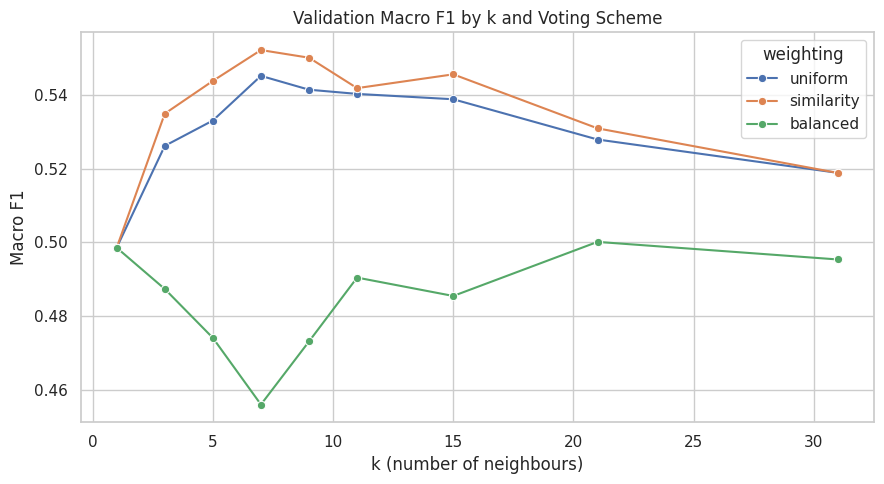

In [33]:
rows = []
for weighting in WEIGHTINGS:
    for k in K_VALUES:
        pred = vote(val_idx, val_sim, y_train, k, weighting, class_freq).argmax(axis=1)
        rows.append({
            "weighting": weighting,
            "k": k,
            "accuracy": accuracy_score(y_val, pred),
            "macro_f1": f1_score(y_val, pred, average="macro"),
        })

tuning_df = pd.DataFrame(rows)
display(tuning_df.sort_values("macro_f1", ascending=False).head(10).round(4))

best = tuning_df.sort_values("macro_f1", ascending=False).iloc[0]
BEST_K, BEST_WEIGHTING = int(best["k"]), best["weighting"]
print(f"\nBest on validation -> k={BEST_K}, weighting={BEST_WEIGHTING}, "
      f"Macro F1={best['macro_f1']:.4f}, Accuracy={best['accuracy']:.4f}")

plt.figure(figsize=(9, 5))
sns.lineplot(data=tuning_df, x="k", y="macro_f1", hue="weighting", marker="o")
plt.title("Validation Macro F1 by k and Voting Scheme")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Macro F1")
plt.tight_layout()
plt.show()

## 4. Method 2: TF-IDF + Support Vector Machine (SVM)

**Pipeline:** `TF-IDF word weights -> Linear SVM -> category`

**Idea:** TF-IDF turns each question into a vector of word weights, and a Linear SVM learns to separate the six categories.

- Input text: one of `TFIDF_Text`, `TFIDF_No_Stopwords` or `TFIDF_Stemmed` (prepared in 2.5), chosen on the **validation** set
- Same train / validation / test split as the Arabic-SBERT + KNN method

**Plan:**
1. Try diffrent settings and pick the best one fron the validation set results
2. Train the final model with the picked settings on the training set
3. Evaluate the final model once on the test set
4. Save the results for Section 5

### 4.1 Imports and Setup for Method 2

In [34]:
# import the necessary libraries
import joblib
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# These three text versions we will compare on the validation set
TEXT_COLS = ["TFIDF_Text", "TFIDF_No_Stopwords", "TFIDF_Stemmed"]

### 4.2 Choosing the Best Settings on the Validation Set


Every combination on the option bellowis trained on the **training** set and scored on the **validation** set, so the test set stays untouched.

| Option | Values | Why |
|---|---|---|
| Text version | plain / no stopwords / stemmed | to pick the best preprocessing on the validation set (Section 2.5) |
| N-gram range | (1,1), (1,2) | single words only vs. words + word pairs |
| Class weight | none / balanced | handles the class imbalance |
| C | 0.1, 0.5, 1.0 | how strictly the SVM fits the training data |

**macro F1** is the main metric because every category counts equally, which matters with imbalanced data, and accuracy alone hides poor results on the small categories.

In [35]:
svm_results = []                                                                            #every experiment is stored here

NGRAM_OPT = [(1, 1), (1, 2)]
CLASS_WEIGHT_OPT = ["none", "balanced"]
C_OPT = [0.1, 0.5, 1.0]

for text_col in TEXT_COLS:
    for ngram in NGRAM_OPT:
        vec = TfidfVectorizer(
            ngram_range=ngram,
            min_df=2,                                                                       #min_df=2 drops rare typos as it ignore terms that appear in fewer than 2 questions
            sublinear_tf=True                                                               #sublinear_tf dampens repeated words using 1 + log(count)
        )
        Xtr_tfidf = vec.fit_transform(train_df[text_col])
        Xval_tfidf = vec.transform(val_df[text_col])

        for cw in CLASS_WEIGHT_OPT:
            for C in C_OPT:
                svm = LinearSVC(
                    C=C,
                    class_weight=None if cw == "none" else "balanced",                      #turn the label into the real argument
                    random_state=RANDOM_STATE,
                    max_iter=10000                                                          #enough iterations to avoid convergence warnings
                )
                val_pred = svm.fit(Xtr_tfidf, train_df["Category"]).predict(Xval_tfidf)     #learn from the training questions and predict the validation questions

                svm_results.append({                                                            #store the scores of the experiments
                    "text_col": text_col,
                    "ngram": ngram,
                    "class_weight": cw,
                    "C": C,
                    "val_accuracy": accuracy_score(val_df["Category"], val_pred),
                    "val_macro_f1": f1_score(val_df["Category"], val_pred, average="macro")
                })

#put all results in a table and sort so the best macro F1 is first.
svm_results_df = pd.DataFrame(svm_results).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
svm_results_df.to_csv(OUTPUT_DIR / "Murshed_TFIDF_SVM_validation_results.csv", index=False)

display(svm_results_df.head(10).round(4))                                                    #top 10 combinations

,text_col,ngram,class_weight,C,val_accuracy,val_macro_f1
0,TFIDF_No_Stopwords,"(1, 1)",balanced,0.1,0.8168,0.5857
1,TFIDF_Stemmed,"(1, 2)",balanced,0.1,0.8237,0.5758
2,TFIDF_Text,"(1, 2)",balanced,0.5,0.8222,0.5715
3,TFIDF_Stemmed,"(1, 2)",balanced,0.5,0.8209,0.5710
4,TFIDF_No_Stopwords,"(1, 2)",balanced,0.5,0.8228,0.5674
5,TFIDF_Text,"(1, 2)",balanced,1.0,0.8212,0.5669
6,TFIDF_Stemmed,"(1, 1)",balanced,0.1,0.7918,0.5648
7,TFIDF_No_Stopwords,"(1, 2)",balanced,1.0,0.8215,0.5646
8,TFIDF_Text,"(1, 1)",balanced,0.1,0.8104,0.5639
9,TFIDF_Text,"(1, 1)",balanced,0.5,0.8076,0.5634


In [36]:
#average macro F1 per option to see which choices matter most
for option in ["text_col", "ngram", "class_weight", "C"]:
    print(f"\nAverage validation macro F1 by {option}:")
    print(svm_results_df.groupby(option)["val_macro_f1"].mean().round(4).sort_values(ascending=False))


Average validation macro F1 by text_col:
text_col
TFIDF_Stemmed         0.5254
TFIDF_No_Stopwords    0.5117
TFIDF_Text            0.5085
Name: val_macro_f1, dtype: float64

Average validation macro F1 by ngram:
ngram
(1, 1)    0.5267
(1, 2)    0.5037
Name: val_macro_f1, dtype: float64

Average validation macro F1 by class_weight:
class_weight
balanced    0.5614
none        0.4690
Name: val_macro_f1, dtype: float64

Average validation macro F1 by C:
C
1.0    0.5393
0.5    0.5364
0.1    0.4698
Name: val_macro_f1, dtype: float64


### 4.3 Training the Final Model

The best settings from Section 4.2 are used to train the final model on the **training** set only.

In [37]:
best_svm = svm_results_df.iloc[0]                                                   #best combination on validation
best_text_col = best_svm["text_col"]                                            #best text version
best_ngram = best_svm["ngram"]                                                  #best n-gram range
best_cw = None if best_svm["class_weight"] == "none" else "balanced"            #best class weighting (real argument)
best_C = float(best_svm["C"])                                                   #best C value

print("Best settings:", dict(text=best_text_col, ngram=best_ngram, class_weight=best_cw, C=best_C))
print(f"Validation Macro F1={best_svm['val_macro_f1']:.4f}, Accuracy={best_svm['val_accuracy']:.4f}")

#the Pipeline keeps vectorizer and the SVM together, so the saved model accepts raw text
final_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=best_ngram, min_df=2, sublinear_tf=True)),
    ("svm", LinearSVC(C=best_C, class_weight=best_cw, random_state=RANDOM_STATE, max_iter=10000)),
])

start = time.time()
final_model.fit(train_df[best_text_col], train_df["Category"])               #train on the training set only
train_time = time.time() - start

joblib.dump(final_model, OUTPUT_DIR / "Murshed_TFIDF_SVM.joblib")            #saves vectorizer + SVM together in one file
print(f"Training time: {train_time:.2f} s")

Best settings: {'text': 'TFIDF_No_Stopwords', 'ngram': (1, 1), 'class_weight': 'balanced', 'C': 0.1}
Validation Macro F1=0.5857, Accuracy=0.8168
Training time: 2.21 s


## 5. Model Comparison and Final Evaluation

### 5.1 - 3.6 Final Evaluation on the Test Set: SEBERT KNN (Method 1)

In [38]:
test_idx, test_sim = top_k_neighbors(X_test, X_train, BEST_K)
test_votes = vote(test_idx, test_sim, y_train, BEST_K, BEST_WEIGHTING, class_freq)
test_pred = test_votes.argmax(axis=1)

test_acc = accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average="macro")
test_weighted_f1 = f1_score(y_test, test_pred, average="weighted")

print(f"Arabic-SBERT + KNN (k={BEST_K}, {BEST_WEIGHTING})")
print(f"Accuracy   : {test_acc:.4f}")
print(f"Macro F1   : {test_macro_f1:.4f}")
print(f"Weighted F1: {test_weighted_f1:.4f}\n")
print(classification_report(y_test, test_pred, target_names=CLASSES, digits=4, zero_division=0))

Arabic-SBERT + KNN (k=7, similarity)
Accuracy   : 0.8199
Macro F1   : 0.5497
Weighted F1: 0.8001

                                           precision    recall  f1-score   support

      Behavioral Psychological Conditions     0.7635    0.5985    0.6710       259
         Childhood Psychological Problems     0.6897    0.8219    0.7500        73
            Neuropsychological Conditions     0.8464    0.9528    0.8965      2290
Other Psychological and Behavioral Issues     0.0000    0.0000    0.0000        24
         Personality and Self Development     0.6742    0.3488    0.4598       344
                      Psychotic Disorders     0.6491    0.4353    0.5211       170

                                 accuracy                         0.8199      3160
                                macro avg     0.6038    0.5262    0.5497      3160
                             weighted avg     0.8002    0.8199    0.8001      3160



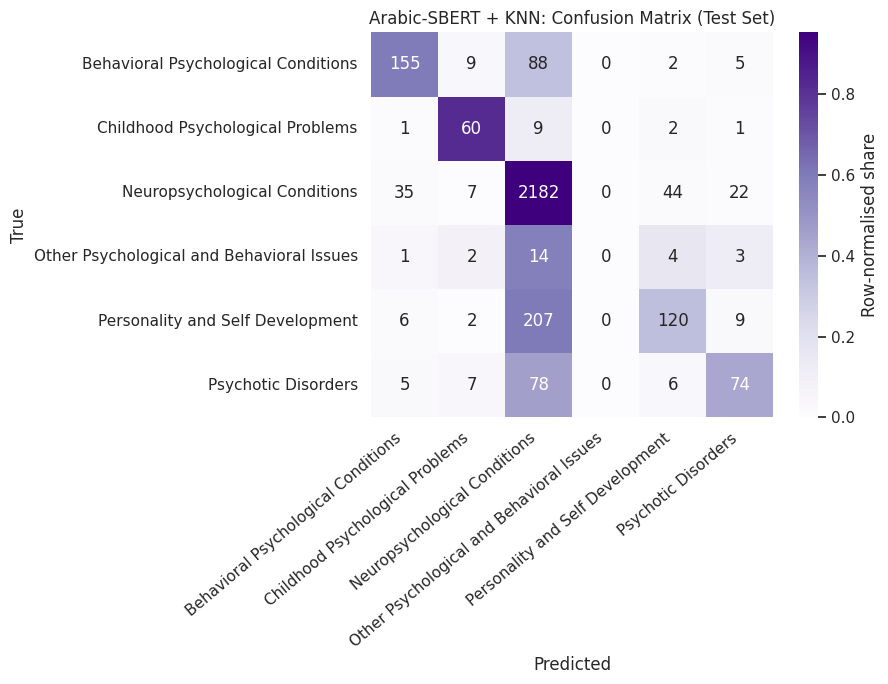

In [39]:
# Row-normalised confusion matrix (each row sums to 1 = recall per class)
cm = confusion_matrix(y_test, test_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Purples",
            xticklabels=CLASSES, yticklabels=CLASSES, cbar_kws={"label": "Row-normalised share"})
plt.title("Arabic-SBERT + KNN: Confusion Matrix (Test Set)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

### 5.1 - 3.7 Error Analysis

In [40]:
wc = lambda s: s.str.split().str.len()
SHORT_THRESHOLD = int(np.percentile(wc(train_m1["SBERT_Text"]), 25))
print("Short-question threshold (words):", SHORT_THRESHOLD)

test_words = wc(test_m1["SBERT_Text"]).values
groups = {"short": test_words <= SHORT_THRESHOLD, "long": test_words > SHORT_THRESHOLD}

rows = []
for name, mask in groups.items():
    rows.append({
        "group": name,
        "n": int(mask.sum()),
        "accuracy": accuracy_score(y_test[mask], test_pred[mask]),
        "macro_f1": f1_score(y_test[mask], test_pred[mask], average="macro"),
    })
short_long_knn = pd.DataFrame(rows)
display(short_long_knn.round(4))

Short-question threshold (words): 78


,group,n,accuracy,macro_f1
0,short,796,0.8028,0.5907
1,long,2364,0.8257,0.5240


In [41]:
# Most frequent confusions (true -> predicted)
pairs = []
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if i != j and cm[i, j] > 0:
            pairs.append((CLASSES[i], CLASSES[j], int(cm[i, j])))
pairs_df = pd.DataFrame(pairs, columns=["True", "Predicted", "Count"]).sort_values("Count", ascending=False)
display(pairs_df.head(8))

# A few misclassified test questions with their nearest training neighbour
wrong = np.where(test_pred != y_test)[0]
rng = np.random.RandomState(RANDOM_STATE)
for i in rng.choice(wrong, size=min(4, len(wrong)), replace=False):
    nn = test_idx[i, 0]
    print("-" * 70)
    print("True:", CLASSES[y_test[i]], "| Predicted:", CLASSES[test_pred[i]])
    print("Question  :", test_m1["SBERT_Text"].iloc[i][:200])
    print(f"Nearest (sim={test_sim[i,0]:.3f}, {CLASSES[y_train[nn]]}):", train_m1["SBERT_Text"].iloc[nn][:200])

,True,Predicted,Count
19,Personality and Self Development,Neuropsychological Conditions,207
1,Behavioral Psychological Conditions,Neuropsychological Conditions,88
23,Psychotic Disorders,Neuropsychological Conditions,78
10,Neuropsychological Conditions,Personality and Self Development,44
8,Neuropsychological Conditions,Behavioral Psychological Conditions,35
11,Neuropsychological Conditions,Psychotic Disorders,22
14,Other Psychological and Behavioral Issues,Neuropsychological Conditions,14
5,Childhood Psychological Problems,Neuropsychological Conditions,9


----------------------------------------------------------------------
True: Personality and Self Development | Predicted: Neuropsychological Conditions
Question  : السلام عليكم. كيف أطور حياتي لأتحول من إنسان يتصرف كالأطفال، ضعيف الثقة بنفسه، إلى إنسان ذكي، واثق من نفسه، لا يخاف من أي شيء؟ أحياناً أتلعثم بالكلام مع الناس، وعندما أراجع نفسي، أقول: أنا في بلد عربي
Nearest (sim=0.809, Other Psychological and Behavioral Issues): السلام عليكم أريد التغيير من نفسي ولا أستطيع توجيه نفسي، فأنا انطوائي، لا أحب الاختلاط مع الأصحاب أو الناس، لأني لا أجيد التحدث أو لا أجد كلاماً أتحدث فيه مع الناس، فأمتنع عن الخروج حتى لا أكون عبئاً 
----------------------------------------------------------------------
True: Psychotic Disorders | Predicted: Neuropsychological Conditions
Question  : السلام عليكم توفي ولد أختي بحادث، الله يرحمه ويغفر له، وأتوا جنازته وذهبنا نسلم عليه ونودعه، لكن أخته كانت تبكي وجاءت تسلم عليه وتقول رأت شخصاً غريباً، ليس من أقاربنا، يلبس الأبيض، واقف عند رأس الجناز
Nearest (sim=0.6

In [42]:
#Save it for future use.
pd.DataFrame({
    "Question": test_m1["SBERT_Text"],
    "True": [CLASSES[i] for i in y_test],
    "Pred_SBERT_KNN": [CLASSES[i] for i in test_pred],
}).to_csv(OUTPUT_DIR / "Predictions_SBERT_KNN.csv", index=False, encoding="utf-8-sig")

with open(OUTPUT_DIR / "Results_SBERT_KNN.json", "w", encoding="utf-8") as f:
    json.dump({
        "model": MODEL_NAME, "max_seq_len": MAX_SEQ_LEN,
        "k": BEST_K, "weighting": BEST_WEIGHTING,
        "accuracy": test_acc, "macro_f1": test_macro_f1, "weighted_f1": test_weighted_f1,
        "short_threshold_words": SHORT_THRESHOLD,
        "short_long": short_long_knn.to_dict(orient="records"),
    }, f, indent=2)
print("Saved predictions and results to", OUTPUT_DIR.resolve())

Saved predictions and results to /content/processed_data


### 5.2- 4.4  Evaluating on the Test Set: TF-IDF + SVM (Method 2)

The trained model is evaluated **once** on the test set. The **macro F1** is the main metric, and the baseline (always guessing the biggest category) shows what the model must beat.

In [43]:
y_test_svm = test_df["Category"]

start = time.time()
y_pred_svm = final_model.predict(test_df[best_text_col])                        #predict the test set (used once)
predict_time = time.time() - start

svm_test_accuracy = accuracy_score(y_test_svm, y_pred_svm)
svm_test_macro_f1 = f1_score(y_test_svm, y_pred_svm, average="macro")                   #average F1 over every category counts
svm_test_weighted_f1 = f1_score(y_test_svm, y_pred_svm, average="weighted")             #average F1 categories weighted by category size

#simple baseline: always predict the most common category
majority_class = train_df["Category"].mode()[0]                             #most frequent category in training
baseline_accuracy = (y_test_svm == majority_class).mean()                       #accuracy of always guessing it

print(f"TF-IDF + SVM ({best_text_col}, ngram={best_ngram}, class_weight={best_cw}, C={best_C})")
print(f"Training time:       {train_time:.2f} s")
print(f"Prediction time:     {predict_time:.2f} s for {len(test_df)} questions")
print(f"Baseline accuracy:   {baseline_accuracy:.4f}  (always '{majority_class}')")
print(f"Test accuracy:       {svm_test_accuracy:.4f}")
print(f"Test macro F1:       {svm_test_macro_f1:.4f}")
print(f"Test weighted F1:    {svm_test_weighted_f1:.4f}")
print()
print(classification_report(y_test_svm, y_pred_svm, digits=3, zero_division=0))      #precision / recall / F1 per category

TF-IDF + SVM (TFIDF_No_Stopwords, ngram=(1, 1), class_weight=balanced, C=0.1)
Training time:       2.21 s
Prediction time:     0.34 s for 3160 questions
Baseline accuracy:   0.7247  (always 'Neuropsychological Conditions')
Test accuracy:       0.8101
Test macro F1:       0.5537
Test weighted F1:    0.8084

                                           precision    recall  f1-score   support

      Behavioral Psychological Conditions      0.661     0.618     0.639       259
         Childhood Psychological Problems      0.544     0.849     0.663        73
            Neuropsychological Conditions      0.896     0.890     0.893      2290
Other Psychological and Behavioral Issues      0.000     0.000     0.000        24
         Personality and Self Development      0.583     0.610     0.597       344
                      Psychotic Disorders      0.533     0.529     0.531       170

                                 accuracy                          0.810      3160
                          

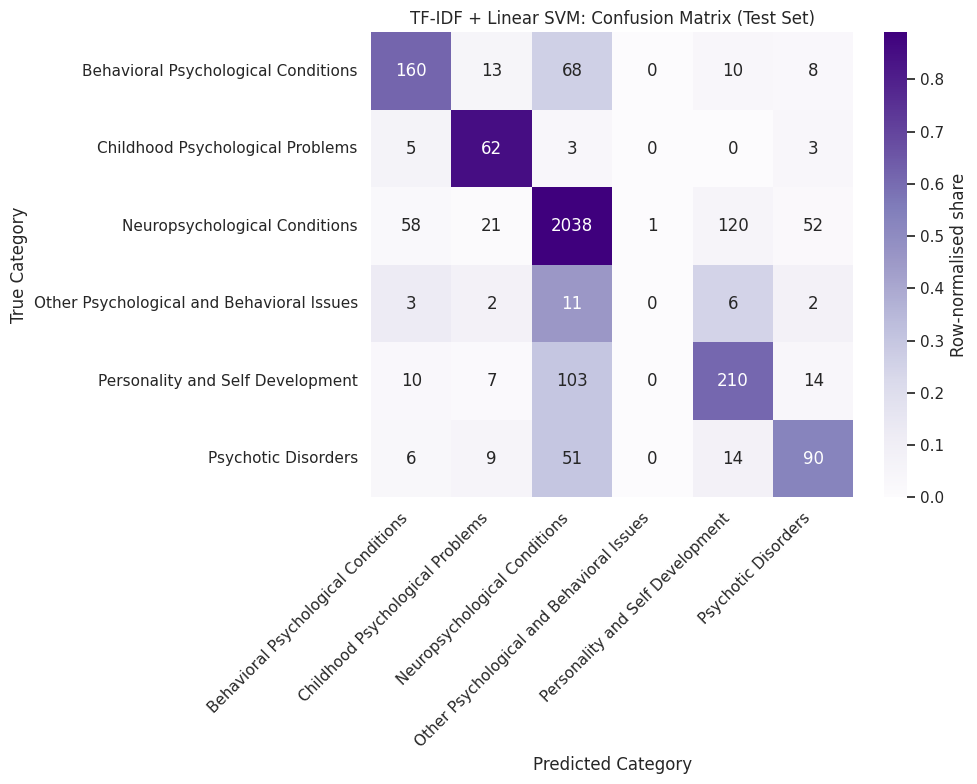

In [44]:
class_names = sorted(y_test_svm.unique())                                        #the six category names in a fixed order

#confusion matrix: rows = true category, columns = predicted category
#normalize="true" turns counts into percentages of each true category, so small classes stay readable
#each row sums to 1 = recall per class
cm_svm = confusion_matrix(y_test_svm, y_pred_svm, labels=class_names)
cm_svm_norm = cm_svm / cm_svm.sum(axis=1, keepdims=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_svm_norm,
    annot=cm_svm,
    fmt="d",
    cmap="Purples",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={"label": "Row-normalised share"}
)
plt.title("TF-IDF + Linear SVM: Confusion Matrix (Test Set)")
plt.xlabel("Predicted Category")
plt.ylabel("True Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Murshed_TFIDF_SVM_confusion_matrix.png", dpi=150)
plt.show()

### 5.2 - 4.5 Error Analysis

In [45]:
#short vs long questions
svm_test_words = wc(test_df["SBERT_Text"]).values
groups = {"short": svm_test_words <= SHORT_THRESHOLD, "long": svm_test_words > SHORT_THRESHOLD}

rows = []
for name, mask in groups.items():
    rows.append({
        "group": name,
        "n": int(mask.sum()),
        "accuracy": accuracy_score(y_test_svm.values[mask], y_pred_svm[mask]),
        "macro_f1": f1_score(y_test_svm.values[mask], y_pred_svm[mask], average="macro"),
    })
short_long_svm = pd.DataFrame(rows)
display(short_long_svm.round(4))

,group,n,accuracy,macro_f1
0,short,796,0.7764,0.5684
1,long,2364,0.8215,0.5407


In [46]:
# Most frequent confusions (true -> predicted)
pairs = []
for i, true_cat in enumerate(class_names):
    for j, pred_cat in enumerate(class_names):
        if i != j and cm_svm[i, j] > 0:
            pairs.append((true_cat, pred_cat, int(cm_svm[i, j])))
svm_pairs_df = pd.DataFrame(pairs, columns=["True", "Predicted", "Count"]).sort_values("Count", ascending=False)
display(svm_pairs_df.head(8))

# A few misclassified test questions
wrong = np.where(y_pred_svm != y_test_svm.values)[0]
rng = np.random.RandomState(RANDOM_STATE)
for i in rng.choice(wrong, size=min(4, len(wrong)), replace=False):
    print("-" * 70)
    print("True:", y_test_svm.iloc[i], "| Predicted:", y_pred_svm[i])
    print("Question:", test_df["SBERT_Text"].iloc[i][:200])

,True,Predicted,Count
10,Neuropsychological Conditions,Personality and Self Development,120
19,Personality and Self Development,Neuropsychological Conditions,103
1,Behavioral Psychological Conditions,Neuropsychological Conditions,68
7,Neuropsychological Conditions,Behavioral Psychological Conditions,58
11,Neuropsychological Conditions,Psychotic Disorders,52
23,Psychotic Disorders,Neuropsychological Conditions,51
8,Neuropsychological Conditions,Childhood Psychological Problems,21
24,Psychotic Disorders,Personality and Self Development,14


----------------------------------------------------------------------
True: Psychotic Disorders | Predicted: Personality and Self Development
Question: أبلغ من العمر 30 سنة- متزوجة، - لدي 3 أطفال- خريجة خدمة اجتماعية، حاصلة على الماجستير بتقدير ممتاز، موظفة حاليا بمدرسة أهلية كمرشدة طلابية، أقوم بما يطلب مني على الوجه المطلوب. والعمل ليس كثير أو مجهد
----------------------------------------------------------------------
True: Personality and Self Development | Predicted: Behavioral Psychological Conditions
Question: السلام عليكم ورحمة الله وبركاته.. تم تشخيص حالة خطيبي وشقيقاته أنهم يعانون من الاضطراب السلوكي لحركة العين السريعة، التي تسمى (Rapid eye movement diorder)، حيث بدأ بتنفيذ حركات في يده ورجله أثناء نومه
----------------------------------------------------------------------
True: Childhood Psychological Problems | Predicted: Neuropsychological Conditions
Question: السلام عليكم ورحمة الله وبركاته أنا أم لبنت وولد، مشكلتي من بعد ولادتي بولدي نفسيتي متعبة وحزينة، بسبب أن ابني مص

In [47]:
#Which words push the SVM towards each category? this helps explain the results
feature_names = np.array(final_model.named_steps["tfidf"].get_feature_names_out())     #the fitted vectorizer inside the pipeline it is in the same order as the SVM
svm_coef = final_model.named_steps["svm"].coef_                                        #the fitted SVM inside the pipeline

for i, category in enumerate(final_model.named_steps["svm"].classes_):                 #svm_coef has one row of word weights per category
    top_idx = np.argsort(svm_coef[i])[-10:][::-1]                                      #indices of the 10 largest weights
    print(f"{category}:\n    " + ", ".join(feature_names[top_idx]))

Behavioral Psychological Conditions:
    النوم, الارق, انام, التبول, احلام, اليقظة, رعشة, نومي, الرعشة, اللاارادي
Childhood Psychological Problems:
    ابني, ابنتي, عمره, الاطفال, عمرها, الصرع, طفلي, سنوات, الطفل, يبلغ
Neuropsychological Conditions:
    الوسواس, الخوف, وسواس, اخاف, الموت, الوساوس, خوف, القلب, القلق, القهري
Other Psychological and Behavioral Issues:
    الكبت, استيعاب, القطارات, والنفسي, بالطعام, ياكل, اعالج, الامهات, المعنوي, سابقا
Personality and Self Development:
    وقتي, الشخصية, العصبية, شخصيتي, الثقة, اغضب, المزاج, الغضب, انظم, ادرس
Psychotic Disorders:
    الفصام, التركيز, النسيان, الذهان, الذاكرة, بالفصام, انسى, الحفظ, تركيز, السرحان


In [48]:
#saveing the results for future use
pd.DataFrame({
    "Question": test_df["SBERT_Text"].values,
    "True": y_test_svm.values,
    "Pred_TFIDF_SVM": y_pred_svm,
}).to_csv(OUTPUT_DIR / "Predictions_TFIDF_SVM.csv",
          index=False,
          encoding="utf-8-sig")

metrics = {
    "method": "TF-IDF + Linear SVM",
    "best_settings": {"text_col": best_text_col,
                      "ngram": list(best_ngram),
                      "class_weight": best_cw,
                      "C": best_C},
    "accuracy": float(svm_test_accuracy),
    "macro_f1": float(svm_test_macro_f1),
    "weighted_f1": float(svm_test_weighted_f1),
    "baseline_accuracy": float(baseline_accuracy),
    "train_time_seconds": round(train_time, 2),
    "short_threshold_words": SHORT_THRESHOLD,
    "short_long": short_long_svm.to_dict(orient="records"),
}
with open(OUTPUT_DIR / "Murshed_TFIDF_SVM.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False)

print("Saved predictions and results to", OUTPUT_DIR.resolve())

Saved predictions and results to /content/processed_data


## 5.3 Side-by-Side Comparison: Arabic-SBERT + KNN vs. TF-IDF + SVM

Both methods use the **same** train / validation / test split, were tuned on the validation set only, and are evaluated once on the same test questions. Because the data is imbalanced, **Macro F1** is the main metric and accuracy is secondary. The majority-class baseline shows what a model that always answers "Neuropsychological Conditions" would score.

Overall test-set results (Macro F1 is the main metric):


,Accuracy,Macro F1,Macro Precision,Macro Recall,Weighted F1
Method,,,,,
"Arabic-SBERT + KNN (k=7, similarity)",0.8199,0.5497,0.6038,0.5262,0.8001
TF-IDF + Linear SVM,0.8101,0.5537,0.5362,0.5828,0.8084
Majority baseline,0.7247,0.1401,0.1208,0.1667,0.6090



Per-class results:


,Support,KNN Precision,SVM Precision,KNN Recall,SVM Recall,KNN F1,SVM F1,F1 diff (KNN - SVM)
Behavioral Psychological Conditions,259,0.764,0.661,0.598,0.618,0.671,0.639,0.032
Childhood Psychological Problems,73,0.690,0.544,0.822,0.849,0.750,0.663,0.087
Neuropsychological Conditions,2290,0.846,0.896,0.953,0.890,0.896,0.893,0.003
Other Psychological and Behavioral Issues,24,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Personality and Self Development,344,0.674,0.583,0.349,0.610,0.460,0.597,-0.137
Psychotic Disorders,170,0.649,0.533,0.435,0.529,0.521,0.531,-0.010



Short (<= 78 words) vs long questions:


,n,accuracy (KNN),macro_f1 (KNN),accuracy (SVM),macro_f1 (SVM)
group,,,,,
short,796,0.8028,0.5907,0.7764,0.5684
long,2364,0.8257,0.5240,0.8215,0.5407


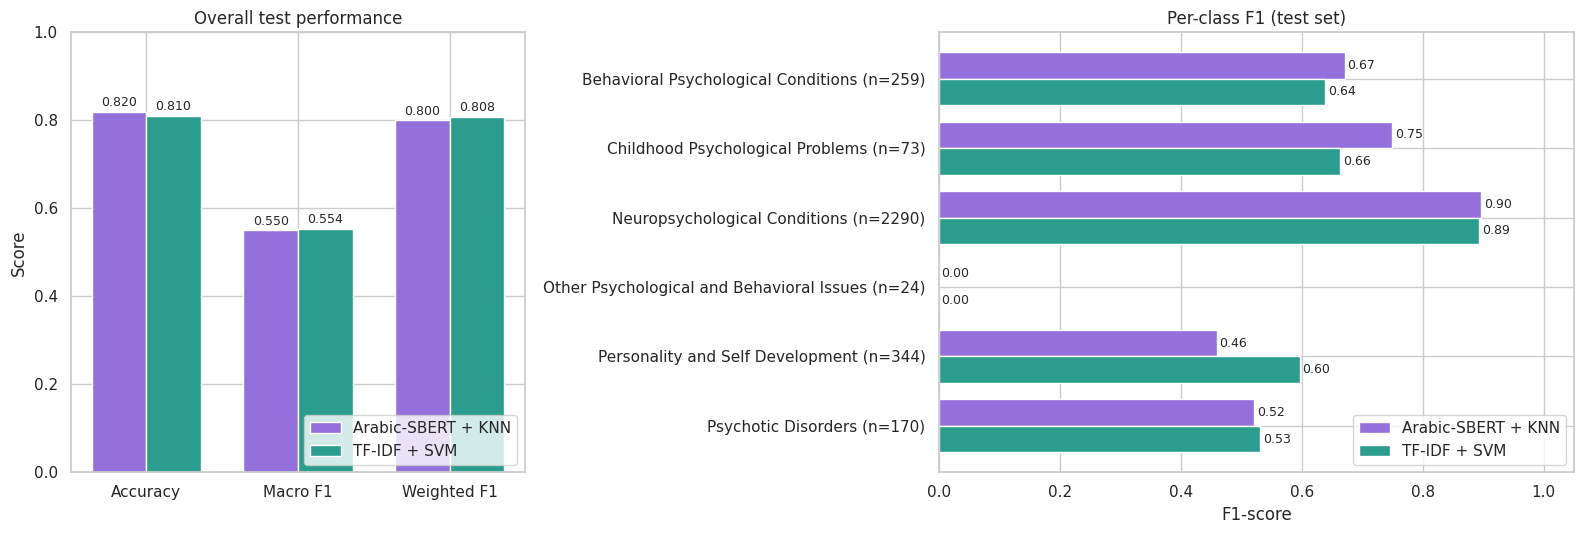

In [49]:
#Imports needed for the comparision
from scipy.stats import binomtest
from sklearn.metrics import precision_recall_fscore_support

y_true  = y_test_svm.values                          # true categories (strings)
knn_pred = np.array(CLASSES)[test_pred]              # Method 1 predictions (strings)
svm_pred = np.asarray(y_pred_svm)                    # Method 2 predictions (strings)

# Both methods must have been evaluated on identical test rows in identical order:
assert len(y_true) == len(knn_pred) == len(svm_pred)
assert (np.array(CLASSES)[y_test] == y_true).all(), "Test sets are not aligned"

KNN_NAME = f"Arabic-SBERT + KNN (k={BEST_K}, {BEST_WEIGHTING})"
SVM_NAME = "TF-IDF + Linear SVM"
BASE_NAME = "Majority baseline"
base_pred = np.full(len(y_true), majority_class)

def summarize(name, pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, labels=CLASSES,
                                                 average="macro", zero_division=0)
    return {"Method": name,
            "Accuracy": accuracy_score(y_true, pred),
            "Macro F1": f,
            "Macro Precision": p,
            "Macro Recall": r,
            "Weighted F1": f1_score(y_true, pred, average="weighted", zero_division=0)}

overall = pd.DataFrame([summarize(KNN_NAME, knn_pred),
                        summarize(SVM_NAME, svm_pred),
                        summarize(BASE_NAME, base_pred)]).set_index("Method")

metric_cols = list(overall.columns)
print("Overall test-set results (Macro F1 is the main metric):")
display(overall.style.format("{:.4f}")
        .highlight_max(subset=pd.IndexSlice[[KNN_NAME, SVM_NAME], metric_cols], color="#d8c7f0"))

p_k, r_k, f_k, support = precision_recall_fscore_support(y_true, knn_pred, labels=CLASSES, zero_division=0)
p_s, r_s, f_s, _       = precision_recall_fscore_support(y_true, svm_pred, labels=CLASSES, zero_division=0)

per_class = pd.DataFrame({
    "Support": support,
    "KNN Precision": p_k, "SVM Precision": p_s,
    "KNN Recall": r_k,    "SVM Recall": r_s,
    "KNN F1": f_k,        "SVM F1": f_s,
    "F1 diff (KNN - SVM)": f_k - f_s,
}, index=CLASSES)

print("\nPer-class results:")
display(per_class.style.format({c: "{:.3f}" for c in per_class.columns if c != "Support"})
        .background_gradient(subset=["F1 diff (KNN - SVM)"], cmap="PuOr", vmin=-0.3, vmax=0.3))

sl = (short_long_knn.set_index("group")[["n", "accuracy", "macro_f1"]]
      .join(short_long_svm.set_index("group")[["accuracy", "macro_f1"]],
            lsuffix=" (KNN)", rsuffix=" (SVM)"))
print(f"\nShort (<= {SHORT_THRESHOLD} words) vs long questions:")
display(sl.style.format({c: "{:.4f}" for c in sl.columns if c != "n"}))

KNN_COLOR, SVM_COLOR = "mediumpurple", "#2a9d8f"
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})

# (a) overall metrics
ax = axes[0]
names = ["Accuracy", "Macro F1", "Weighted F1"]
x = np.arange(len(names)); w = 0.36
kv = [overall.loc[KNN_NAME, m] for m in names]
sv = [overall.loc[SVM_NAME, m] for m in names]
b1 = ax.bar(x - w/2, kv, w, label="Arabic-SBERT + KNN", color=KNN_COLOR)
b2 = ax.bar(x + w/2, sv, w, label="TF-IDF + SVM", color=SVM_COLOR)
ax.bar_label(b1, fmt="%.3f", padding=2, fontsize=9)
ax.bar_label(b2, fmt="%.3f", padding=2, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(names)
ax.set_ylim(0, 1.0); ax.set_ylabel("Score")
ax.set_title("Overall test performance")
ax.legend(loc="lower right")

# (b) per-class F1
ax = axes[1]
y = np.arange(len(CLASSES)); h = 0.38
b1 = ax.barh(y - h/2, per_class["KNN F1"], h, label="Arabic-SBERT + KNN", color=KNN_COLOR)
b2 = ax.barh(y + h/2, per_class["SVM F1"], h, label="TF-IDF + SVM", color=SVM_COLOR)
ax.bar_label(b1, fmt="%.2f", padding=2, fontsize=9)
ax.bar_label(b2, fmt="%.2f", padding=2, fontsize=9)
ax.set_yticks(y)
ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(CLASSES, per_class["Support"])])
ax.invert_yaxis()
ax.set_xlim(0, 1.05); ax.set_xlabel("F1-score")
ax.set_title("Per-class F1 (test set)")
ax.legend(loc="lower right")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "Murshed_Model_Comparison.png", dpi=150, bbox_inches="tight")
plt.show()

In [50]:
# Do the two methods make the same mistakes? Is the difference real?
knn_ok = knn_pred == y_true
svm_ok = svm_pred == y_true

agree = pd.DataFrame(
    {"Questions": [(knn_ok & svm_ok).sum(), (knn_ok & ~svm_ok).sum(),
                   (~knn_ok & svm_ok).sum(), (~knn_ok & ~svm_ok).sum()]},
    index=["Both correct", "Only KNN correct", "Only SVM correct", "Both wrong"])
agree["Share"] = agree["Questions"] / len(y_true)
display(agree.style.format({"Share": "{:.1%}"}))
print(f"If we could always pick the better of the two: accuracy would be "
      f"{(knn_ok | svm_ok).mean():.4f} (best single method: "
      f"{max(knn_ok.mean(), svm_ok.mean()):.4f})")

# Exact McNemar test on accuracy (paired: same test questions)
b, c = int((knn_ok & ~svm_ok).sum()), int((~knn_ok & svm_ok).sum())
p_mcnemar = binomtest(b, b + c, 0.5).pvalue if (b + c) > 0 else 1.0
print(f"\nMcNemar exact test (accuracy): KNN-only={b}, SVM-only={c}, p = {p_mcnemar:.4f}")

y_int   = y_test
knn_int = test_pred
svm_int = le.transform(svm_pred)
rng_bs = np.random.RandomState(RANDOM_STATE)
n = len(y_int)
labels_int = list(range(N_CLASSES))
diffs = []
for _ in range(1000):
    idx = rng_bs.randint(0, n, n)
    diffs.append(f1_score(y_int[idx], knn_int[idx], labels=labels_int, average="macro", zero_division=0)
                 - f1_score(y_int[idx], svm_int[idx], labels=labels_int, average="macro", zero_division=0))
lo, hi = np.percentile(diffs, [2.5, 97.5])
obs = overall.loc[KNN_NAME, "Macro F1"] - overall.loc[SVM_NAME, "Macro F1"]
print(f"Macro F1 difference (KNN - SVM): {obs:+.4f}   95% bootstrap CI [{lo:+.4f}, {hi:+.4f}]")
if lo <= 0 <= hi:
    print("-> The interval contains 0: the difference in Macro F1 is NOT clearly different from chance.")
else:
    print("-> The interval excludes 0: the difference in Macro F1 is reliable.")

sample_idx = np.random.RandomState(RANDOM_STATE).choice(len(test_df), size=256, replace=False)
sample_knn_text = test_m1["SBERT_Text"].iloc[sample_idx].tolist()
sample_svm_text = test_df[best_text_col].iloc[sample_idx]

model.encode(sample_knn_text[:8], normalize_embeddings=True)             # warm-up
t0 = time.time()
emb = model.encode(sample_knn_text, batch_size=64, normalize_embeddings=True, convert_to_numpy=True)
i_, s_ = top_k_neighbors(emb.astype(np.float32), X_train, BEST_K)
_ = vote(i_, s_, y_train, BEST_K, BEST_WEIGHTING, class_freq).argmax(axis=1)
knn_ms = (time.time() - t0) / len(sample_idx) * 1000

t0 = time.time()
_ = final_model.predict(sample_svm_text)
svm_ms = (time.time() - t0) / len(sample_idx) * 1000

cost = pd.DataFrame({
    "Needs training": ["No (embeddings computed once, then cached)", f"Yes ({train_time:.1f} s)"],
    "Needs a neural model at inference": ["Yes (Arabic-SBERT)", "No"],
    "Inference (ms / question)": [f"{knn_ms:.2f}  on {device}", f"{svm_ms:.3f}  on CPU"],
}, index=[KNN_NAME, SVM_NAME])
display(cost)

best_acc = KNN_NAME if overall.loc[KNN_NAME, "Accuracy"] >= overall.loc[SVM_NAME, "Accuracy"] else SVM_NAME
best_f1  = KNN_NAME if overall.loc[KNN_NAME, "Macro F1"] >= overall.loc[SVM_NAME, "Macro F1"] else SVM_NAME
print("\n" + "=" * 70)
print("SUMMARY")
print("=" * 70)
print(f"Highest accuracy : {best_acc} ({overall.loc[best_acc, 'Accuracy']:.4f})")
print(f"Highest Macro F1 : {best_f1} ({overall.loc[best_f1, 'Macro F1']:.4f})")
print(f"Both beat the majority baseline accuracy of {overall.loc[BASE_NAME, 'Accuracy']:.4f}"
      if min(overall.loc[KNN_NAME, 'Accuracy'], overall.loc[SVM_NAME, 'Accuracy']) > overall.loc[BASE_NAME, 'Accuracy']
      else "At least one method does NOT beat the majority baseline accuracy.")
wins_knn = [cl for cl, d in per_class["F1 diff (KNN - SVM)"].items() if d > 0.02]
wins_svm = [cl for cl, d in per_class["F1 diff (KNN - SVM)"].items() if d < -0.02]
print("Classes where KNN is clearly better (F1 +0.02 or more):", wins_knn or "none")
print("Classes where SVM is clearly better (F1 +0.02 or more):", wins_svm or "none")
zero_both = [cl for cl in CLASSES if per_class.loc[cl, "KNN F1"] == 0 and per_class.loc[cl, "SVM F1"] == 0]
if zero_both:
    print("Classes neither method can detect (F1 = 0):", zero_both)

,Questions,Share
Both correct,2321,73.4%
Only KNN correct,270,8.5%
Only SVM correct,239,7.6%
Both wrong,330,10.4%


If we could always pick the better of the two: accuracy would be 0.8956 (best single method: 0.8199)

McNemar exact test (accuracy): KNN-only=270, SVM-only=239, p = 0.1836
Macro F1 difference (KNN - SVM): -0.0040   95% bootstrap CI [-0.0271, +0.0180]
-> The interval contains 0: the difference in Macro F1 is NOT clearly different from chance.


,Needs training,Needs a neural model at inference,Inference (ms / question)
"Arabic-SBERT + KNN (k=7, similarity)","No (embeddings computed once, then cached)",Yes (Arabic-SBERT),2.84 on cuda
TF-IDF + Linear SVM,Yes (2.2 s),No,0.223 on CPU



SUMMARY
Highest accuracy : Arabic-SBERT + KNN (k=7, similarity) (0.8199)
Highest Macro F1 : TF-IDF + Linear SVM (0.5537)
Both beat the majority baseline accuracy of 0.7247
Classes where KNN is clearly better (F1 +0.02 or more): ['Behavioral Psychological Conditions', 'Childhood Psychological Problems']
Classes where SVM is clearly better (F1 +0.02 or more): ['Personality and Self Development']
Classes neither method can detect (F1 = 0): ['Other Psychological and Behavioral Issues']


## 6. Mental Health Question Classification (Try it!)


### 6.1 - 3.8 SBERT-KNN (Method 1):
Important Note: Run all cells above once (embeddings are cached after the first run), then run the next cell and type an Arabic question when prompted.

The result is an **informational classification only, not a medical diagnosis**.

In [51]:
# Final index for the demo: train + validation questions (more neighbours to search)
index_emb = np.vstack([X_train, X_val])
index_y = np.concatenate([y_train, y_val])
index_text = pd.concat([train_m1["SBERT_Text"], val_m1["SBERT_Text"]]).reset_index(drop=True)
index_freq = np.bincount(index_y, minlength=N_CLASSES).astype(float)

GUIDANCE = {
    "Neuropsychological Conditions":
        "يُنصح بمراجعة عيادة الطب النفسي المتخصصة في حالات مثل الاكتئاب والقلق والوسواس.",
    "Personality and Self Development":
        "يُنصح بمراجعة عيادة الإرشاد النفسي المتخصصة في الشخصية وتطوير الذات.",
    "Behavioral Psychological Conditions":
        "يُنصح بمراجعة عيادة العلاج النفسي والسلوكي لتقييم حالتك.",
    "Psychotic Disorders":
        "يُنصح بمراجعة عيادة الطب النفسي المتخصصة في الاضطرابات الذهانية في أقرب وقت ممكن.",
    "Childhood Psychological Problems":
        "يُنصح بمراجعة عيادة الصحة النفسية للأطفال والمراهقين.",
    "Other Psychological and Behavioral Issues":
        "يُنصح بمراجعة عيادة الصحة النفسية العامة لتقييم حالتك وتوجيهك للتخصص المناسب.",
}
DISCLAIMER = "ملاحظة: هذه النتيجة تصنيف معلوماتي وليست تشخيصًا طبيًا."


def classify_question(question, k=BEST_K, weighting=BEST_WEIGHTING, show_neighbors=3):
    question = str(question).strip()
    if not question:
        print("Please enter a question.")
        return None
    text = basic_cleaning(question)          # same cleaning used for SBERT_Text
    q_emb = model.encode([text], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)
    idx, sims = top_k_neighbors(q_emb, index_emb, k)
    votes = vote(idx, sims, index_y, k, weighting, index_freq)[0]
    probs = votes / votes.sum()
    order = np.argsort(-probs)
    top = CLASSES[order[0]]

    print("=" * 70)
    print("Question :", question[:150] + ("..." if len(question) > 150 else ""))
    print(f"Category : {top}  (vote share {probs[order[0]]:.0%})")
    print("Runner-up:", f"{CLASSES[order[1]]} ({probs[order[1]]:.0%})")
    print("Guidance :", GUIDANCE[top])
    print(DISCLAIMER)
    if len(text.split()) < 8:
        print("Note: the question is very short, so the result may be unreliable.")
    elif probs[order[0]] < 0.5:
        print("Note: low agreement between neighbours, so the result is uncertain.")
    if show_neighbors:
        print("\nMost similar questions in the dataset:")
        for r in range(show_neighbors):
            j = idx[0, r]
            print(f"  [{sims[0, r]:.3f}] ({CLASSES[index_y[j]]}) {index_text.iloc[j][:100]}...")
    return top


# Quick demo (By the developer, see the next cell for expeimental usage)
classify_question("أشعر بحزن شديد وفقدان للاهتمام بكل شيء منذ عدة أشهر وأعاني من الأرق")

Question : أشعر بحزن شديد وفقدان للاهتمام بكل شيء منذ عدة أشهر وأعاني من الأرق
Category : Neuropsychological Conditions  (vote share 86%)
Runner-up: Behavioral Psychological Conditions (14%)
Guidance : يُنصح بمراجعة عيادة الطب النفسي المتخصصة في حالات مثل الاكتئاب والقلق والوسواس.
ملاحظة: هذه النتيجة تصنيف معلوماتي وليست تشخيصًا طبيًا.

Most similar questions in the dataset:
  [0.660] (Neuropsychological Conditions) السلام عليكم ورحمة الله. إني أعاني من حالةٍ نفسية سيئة جداً، فلا أكف عن البكاء، وقلبي يؤلمني جداً، و...
  [0.651] (Neuropsychological Conditions) السلام عليكم. أنا أعاني من حزن دائم، بحيث أشعر بثقل في صدري وضيق دائم، بالرغم من أني إنسانة اجتماعية...
  [0.646] (Neuropsychological Conditions) السلام عليكم. لقد مضى عليَّ ما يقارب العشر شهور، شهرٌ مليء بالفقد والحزن والخيبة بسبب جميع من هم حول...


'Neuropsychological Conditions'

In [52]:
# Interactive: type your own question (leave empty to skip)
user_question = input("اكتب سؤالك هنا / Enter your question: ")

if user_question.strip():
    try:
        classify_question(user_question)
    except Exception as e:
        print(f" Error while classifying question: {e}")
else:
    print("No question entered.")

اكتب سؤالك هنا / Enter your question: أتلقى الكثير من الرفض باستمرار، سئمت الطلب لأنني أصبحت أخشى الرفض، لكن أشعر بالضجر، ماذا أفعل؟
Question : أتلقى الكثير من الرفض باستمرار، سئمت الطلب لأنني أصبحت أخشى الرفض، لكن أشعر بالضجر، ماذا أفعل؟
Category : Neuropsychological Conditions  (vote share 58%)
Runner-up: Personality and Self Development (42%)
Guidance : يُنصح بمراجعة عيادة الطب النفسي المتخصصة في حالات مثل الاكتئاب والقلق والوسواس.
ملاحظة: هذه النتيجة تصنيف معلوماتي وليست تشخيصًا طبيًا.

Most similar questions in the dataset:
  [0.658] (Neuropsychological Conditions) أنا إنسان دائم التضجر والملل في العمل مع الأهل والأصدقاء! فما هو السبب في ذلك؟...
  [0.641] (Neuropsychological Conditions) أعاني من القلق المستمر والضعف العام، وليس لدي طاقة لعمل أي شيء، ودائماً ما أقوم بتأجيل أعمالي حتى لا...
  [0.635] (Personality and Self Development) السلام عليكم.. أنا بعمر 29 سنة، متخرجة من الجامعة، ولا أعمل، مشكلتي أني عندما أنوي فعل أي عمل أخشى ا...


### 6.2 - 4.6 TF-IDF + SVM (Method 2):

**Important Note:** Run all cells above once, then run the next cells and type an Arabic question when prompted.

The result is an **informational classification only, not a medical diagnosis**.

In [53]:
#GUIDANCE and DISCLAIMER are reused from 6.1
def preprocess_for_svm(question):
    text = normalize_arabic(basic_cleaning(question))            #same cleaning functions as Section 2.4
    if best_text_col != "TFIDF_Text":                            #the other two versions need these extra steps
        tokens = remove_stopwords(tokenize_arabic(text))
        text = " ".join(tokens if best_text_col == "TFIDF_No_Stopwords" else stem_tokens(tokens))
    return text


def classify_question_svm(question):
    question = str(question).strip()
    if not question:
        print("Please enter a question.")
        return None
    scores = final_model.decision_function([preprocess_for_svm(question)])[0]   #one score per category
    classes = final_model.named_steps["svm"].classes_
    order = np.argsort(-scores)
    top = classes[order[0]]

    print("=" * 70)
    print("Question :", question[:150] + ("..." if len(question) > 150 else ""))
    print("Category :", top)
    print("Runner-up:", classes[order[1]])
    print("Guidance :", GUIDANCE[top])
    print(DISCLAIMER)
    if len(basic_cleaning(question).split()) < 8:
        print("Note: the question is very short, so the result may be unreliable.")
    return top


#quick demo (By the developer, see the next cell for experimental usage)
classify_question_svm("أشعر بحزن شديد وفقدان للاهتمام بكل شيء منذ عدة أشهر وأعاني من الأرق")

Question : أشعر بحزن شديد وفقدان للاهتمام بكل شيء منذ عدة أشهر وأعاني من الأرق
Category : Behavioral Psychological Conditions
Runner-up: Neuropsychological Conditions
Guidance : يُنصح بمراجعة عيادة العلاج النفسي والسلوكي لتقييم حالتك.
ملاحظة: هذه النتيجة تصنيف معلوماتي وليست تشخيصًا طبيًا.


'Behavioral Psychological Conditions'

In [54]:
# Interactive: type your own question (leave empty to skip)
user_question = input("اكتب سؤالك هنا / Enter your question: ")

if user_question.strip():
    try:
        classify_question_svm(user_question)
    except Exception as e:
        print(f"Error while classifying question: {e}")
else:
    print("No question entered.")

اكتب سؤالك هنا / Enter your question: أتلقى الكثير من الرفض باستمرار، سئمت الطلب لأنني أصبحت أخشى الرفض، لكن أشعر بالضجر، ماذا أفعل؟
Question : أتلقى الكثير من الرفض باستمرار، سئمت الطلب لأنني أصبحت أخشى الرفض، لكن أشعر بالضجر، ماذا أفعل؟
Category : Personality and Self Development
Runner-up: Neuropsychological Conditions
Guidance : يُنصح بمراجعة عيادة الإرشاد النفسي المتخصصة في الشخصية وتطوير الذات.
ملاحظة: هذه النتيجة تصنيف معلوماتي وليست تشخيصًا طبيًا.
